<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png" alt="LOGO UPCH" width=250 align="right">

<br>
<h1><font color="#7F000E" size=5>UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>
<h1><font color="#7F000E" size=6>SEÑALES BIOMÉDICAS</font></h1>
<h1><font color="#7F000E" size=4>LAB 12 —Tratamiento de la señal EEG, ritmos cerebrales, filtro ICA y extracción de características</font></h1>
<br>
<br>
<div style="text-align:right">
<font color="#7F000E" size=3> Curso: Introducción a las Señales Biomédicas</font><br>
<font color="#7F000E" size=3> Registros: 7 archivos EEG de un participante (BITalino, 08/05/2026)</font><br>
<font color="#7F000E" size=3> Versión para el docente</font><br>
</div>

| Campo | Completar |
|---|---|
| **Nombre del estudiante** | Mariel Andrea Brachowicz Suarez |
| **Código** | 70339347 |
| **Grupo** | G2 |
| **Fecha** | 11/11/26 |

> **Material base:** clase *Tratamiento de señal EEG* (Mg. Lewis De La Cruz) · Ejemplo de MNE-Python [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) · Laboratorio de adquisición de EEG con BITalino.

## 🔑 Cómo usar el laboratorio

Después de cada pregunta ✍️ hay una celda **✅ Respuesta**, construida **solo con las salidas visibles** del cuaderno. Las respuestas que dependen de la teoría y no de estos datos se marcan como *(conceptual)*. El cuestionario final incluye las **celdas de código que lo resuelven**, y hay una celda 🔎 de verificación adicional en B.8.

### Resumen de resultados (nuestros registros)

| Aspecto | Resultado |
|---|---|
| Archivos | 4 registros EEG de 1 canal, Fs = **1000 Hz** (Nyquist = 500 Hz) |
| Dispositivos | Un único BITalino (**30:BA**) para las cuatro condiciones |
| Condiciones | Basal, ojos abiertos, música relajante y música estresante |
| Interferencias | No se detectaron líneas espectrales estrechas significativas ni un pico importante en 40 Hz |
| Saturación | Ojos abiertos: **3.35 %** · música estresante: **0.10 %** · basal y música relajante: **0 %** |
| Ritmos cerebrales | La potencia relativa alfa disminuye de **11.7 %** en basal a **6.7 %** con ojos abiertos |
| ICA de un canal (Wavelet-ICA) | Corrige algunos transitorios bruscos, pero su efecto sobre la clasificación es pequeño |
| Clasificación de 4 condiciones | Mejor F1 macro = **0.521** (Regresión Logística); azar = 0

<a id="indice"></a>
# 📑 Índice de contenido

> 💡 En Colab también puedes navegar con el panel **"Índice"** (ícono ☰ de la barra izquierda).

**[Introducción](#intro)** — ¿Qué haremos? · El EEG en una página · Nuestros datos · Agenda

**[⚙️ Configuración](#config)**

**[🅰️ PARTE A — Conociendo nuestros datos](#parteA)** *(≈ 15 min)*
- [A.1 Subir los archivos e inventario automático](#A1)
- [A.2 Lectura, conversión a µV y saturación](#A2)
- [A.3 Primer vistazo: las señales en el tiempo](#A3)
- [A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?](#A4)
- [A.5 Control de calidad automático](#A5)
- [A.6 Conclusiones de la Parte A](#A6)

**[🅱️ PARTE B — Tratamiento y extracción de características](#parteB)** *(≈ 40 min)*
- [B.1 El pipeline de procesamiento](#B1)
- [B.2 Filtrado](#B2)
- [B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma](#B3)
- [B.4 Filtro ICA: separar el cerebro de los artefactos](#B4)
- [B.5 Normalización y segmentación en épocas](#B5)
- [B.6 Extracción de características](#B6)
- [B.7 La tabla de características](#B7)
- [B.8 Clasificación y una advertencia importante](#B8)
- [B.9 Conclusiones de la Parte B](#B9)

**[📝 Cuestionario final: experimenta con tus datos](#cuestionario)** *(≈ 5 min o como tarea)*

**[📦 Entregables y referencias](#entregables)**

<a id="intro"></a>
# Introducción

## 🎯 ¿Qué haremos hoy?

**Objetivo: limpiar la señal EEG, analizar sus ritmos cerebrales y extraer características que permitan distinguir el estado del participante.**

Seguiremos el pipeline de la clase:

```
Señal fisiológica → Filtrado → Limpieza (ICA) → Preprocesamiento (normalización) → Extracción de características → Ingeniería de características
```

## 🧠 El EEG en una página

**¿Qué es?** El electroencefalograma es la actividad eléctrica registrada en el cuero cabelludo. La generan los **potenciales post-sinápticos** de grandes poblaciones de neuronas de la corteza cerebral que se activan de forma **sincronizada**.

**¿Qué tan grande es?** Muy pequeña: **20–100 µV** en el cuero cabelludo, unas **10 a 50 veces menos** que el ECG. Por eso el EEG es tan sensible al ruido y a los artefactos.

**Ritmos cerebrales.** El EEG se describe por **bandas de frecuencia**, y cada una se asocia a estados distintos:

| Banda | Frecuencia | Estado asociado |
|---|---|---|
| **Delta (δ)** | 0.5 – 4 Hz | Sueño profundo |
| **Theta (θ)** | 4 – 8 Hz | Somnolencia, meditación profunda |
| **Alfa (α)** | 8 – 13 Hz | Relajación con **ojos cerrados**; disminuye al abrir los ojos |
| **Beta (β)** | 13 – 30 Hz | Alerta, concentración, ojos abiertos |
| **Gamma (γ)** | > 30 Hz | Procesamiento cognitivo complejo; muy contaminada por actividad muscular |

> 📖 **Definición fácil:** imagina el EEG como el sonido de una orquesta. Cada banda es una sección de instrumentos: los contrabajos (delta) tocan lento y grave; los violines (beta, gamma), rápido y agudo. Analizar bandas es medir **qué tan fuerte suena cada sección**.

**Artefactos.** Son señales que **no vienen del cerebro** pero aparecen en el registro:

| Artefacto | Origen | Cómo se ve |
|---|---|---|
| **Parpadeo / movimiento ocular** | El ojo es un dipolo eléctrico; se mueve cerca de Fp1/Fp2 | Ondas lentas y grandes (< 4 Hz) |
| **Muscular (EMG)** | Músculos temporal, masetero y frontal (masticar, apretar) | Actividad rápida y "peluda" (> 20 Hz) |
| **Red eléctrica** | Instalación eléctrica (Perú: 60 Hz) | Oscilación de frecuencia fija |

## 🫀 Nuestros datos

Un participante registró su EEG con BITalino usando una **derivación frontal**: electrodo positivo en **Fp1**, negativo en **Fp2** y referencia en **O2**. Es **un solo canal**.

| Archivo | Condición | Duración aprox. |
|---|---|---|
| `Basal1.txt` | Reposo, **ojos cerrados** y cubiertos | 1 min |
| `ojos_abiertos.txt` | Ojos abiertos, mirada fija en un punto | 1 min |
| `basal2.txt` | Reposo con ojos cerrados, después de abrir los ojos | 30 s |
| `parpadeo_masticacion.txt` | Parpadeo rápido y masticación continua (**artefactos a propósito**) | 1 min |
| `basal3.txt` | Reposo con ojos cerrados, después de los artefactos | 30 s |
| `musica_relajante.txt` | Ojos cerrados escuchando música relajante | 1 min |
| `musica_estresante.txt` | Ojos cerrados escuchando música estresante | 1 min |

El cuaderno reconoce la condición por palabras clave en el nombre del archivo: `basal`, `ojos`, `parpadeo`/`mastic`, `relaj`, `estres`. No importan las mayúsculas.

## ⏱️ Agenda (60 min)

| Parte | Contenido | Minutos |
|---|---|---:|
| Configuración | Librerías y carga de archivos | 0 – 5 |
| **A** | Conocer los datos: inventario, saturación, espectro y calidad | 5 – 20 |
| **B** | Filtrado → bandas → ICA → épocas → características → clasificación | 20 – 55 |
| Cuestionario | Experimentos con tus datos | 55 – 60 (o tarea) |

<a id="config"></a>
# ⚙️ Configuración

| Librería | Para qué la usamos |
|---|---|
| `numpy`, `pandas` | Números y tablas |
| `matplotlib` | Gráficas |
| `scipy.signal` | Filtros y espectro (método de Welch) |
| `pywt` (PyWavelets) | Descomposición wavelet (para el ICA de un canal) |
| `scikit-learn` | FastICA, clasificadores y validación |

In [1]:
# PyWavelets no siempre viene en Colab: se instala solo si falta
try:
    import pywt
except ImportError:
    !pip install -q PyWavelets
    import pywt

import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import skew, kurtosis
from sklearn.decomposition import FastICA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold", "font.size": 11})
np.random.seed(0)

ORDEN = ["basal", "ojos_abiertos", "parpadeo_masticacion", "musica_relajante", "musica_estresante"]
COLOR = {"basal": "tab:blue", "ojos_abiertos": "tab:orange", "parpadeo_masticacion": "tab:red",
         "musica_relajante": "tab:green", "musica_estresante": "tab:purple"}
BANDAS = {"delta": (1, 4), "theta": (4, 8), "alfa": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
COLOR_BANDA = {"delta": "#4C72B0", "theta": "#55A868", "alfa": "#C44E52", "beta": "#8172B2", "gamma": "#CCB974"}
print("✅ Librerías listas | PyWavelets", pywt.__version__)

✅ Librerías listas | PyWavelets 1.8.0


---
<a id="parteA"></a>
# 🅰️ PARTE A — Conociendo nuestros datos *(≈ 15 min)*

> **Idea central:** antes de aplicar ICA o calcular características, **revisamos los datos**. En el EEG esto es todavía más importante que en el ECG: la señal es diminuta y cualquier problema de adquisición puede ser más grande que el propio cerebro.

[⬆️ Volver al índice](#indice)

<a id="A1"></a>
## A.1 Subir los archivos e inventario automático

Ejecuta la celda. En Colab se abrirá un botón para **subir tus archivos `.txt`**; puedes seleccionarlos todos a la vez. El cuaderno:
1. Busca todos los `.txt` cuyo sensor sea **EEG** (lo lee en la cabecera).
2. Deduce la **condición** a partir del nombre del archivo.

> Si no hay archivos, se generan **registros simulados** solo para poder recorrer el cuaderno.

In [2]:
def condicion_desde_nombre(nombre):
    n = nombre.lower()
    if "basal" in n:                       return "basal"
    if "ojos" in n:                        return "ojos_abiertos"
    if "parpad" in n or "mastic" in n:     return "parpadeo_masticacion"
    if "relaj" in n:                       return "musica_relajante"
    if "estres" in n:                      return "musica_estresante"
    return os.path.splitext(os.path.basename(n))[0]

def leer_cabecera(ruta):
    with open(ruta, "r", encoding="utf-8", errors="ignore") as f:
        lineas = [f.readline() for _ in range(3)]
    return list(json.loads(lineas[1].lstrip("# ").strip()).values())[0]

def buscar_archivos():
    filas = []
    for ruta in sorted(glob.glob("*.txt")):
        try:
            meta = leer_cabecera(ruta)
        except Exception:
            continue
        if any("EEG" in s.upper() for s in meta.get("sensor", [])):
            filas.append({"archivo": ruta, "condicion": condicion_desde_nombre(ruta)})
    return pd.DataFrame(filas, columns=["archivo", "condicion"])

inventario = buscar_archivos()
if len(inventario) == 0:
    try:
        from google.colab import files
        print("📤 Sube tus archivos .txt de OpenSignals (selecciónalos todos a la vez):")
        files.upload()
        inventario = buscar_archivos()
    except ImportError:
        pass

MODO_DEMO = inventario["condicion"].nunique() < 2 if len(inventario) else True
print("Modo:", "⚠️ DEMOSTRACIÓN (datos simulados)" if MODO_DEMO else "✅ datos reales del grupo")

Modo: ✅ datos reales del grupo


In [3]:
# ---- Solo en modo demostración: genera 3 registros EEG simulados ----
def generar_eeg_demo(ruta, alfa, beta, parpadeos, emg, dur=60, fs=100, semilla=0):
    rng = np.random.default_rng(semilla)
    t = np.arange(int(dur * fs)) / fs
    x = np.cumsum(rng.standard_normal(len(t))) * 0.05                     # fondo 1/f
    x = signal.detrend(x) + 1.5 * rng.standard_normal(len(t))
    def ritmo(lo, hi):                                                   # ruido filtrado: ritmo "ancho", no una línea
        b, a = signal.butter(4, [lo, hi], "bandpass", fs=fs)
        r = signal.filtfilt(b, a, rng.standard_normal(len(t)))
        return r / r.std()
    x += alfa * ritmo(8, 12) + beta * ritmo(15, 25)
    for tp in rng.uniform(1, dur - 1, parpadeos):                        # parpadeos
        x += 25 * np.exp(-((t - tp)**2) / (2 * 0.08**2))
    if emg:                                                              # ráfagas musculares
        env = (np.sin(2*np.pi*0.8*t) > 0.3).astype(float)
        b, a = signal.butter(4, [20, 45], "bandpass", fs=fs)
        x += emg * env * signal.lfilter(b, a, rng.standard_normal(len(t)))
    adc = np.clip(np.round((x / 1e6 * 41782 / 3.3 + 0.5) * 1024), 0, 1023).astype(int)
    meta = {"demo": {"sensor": ["EEGBITREV"], "column": ["nSeq", "I1", "I2", "O1", "O2", "A4"], "label": ["A4"],
                     "sampling rate": fs, "resolution": [4, 1, 1, 1, 1, 10], "date": "DEMO", "time": "00:00:00",
                     "device name": "DEMO"}}
    with open(ruta, "w") as f:
        f.write("# OpenSignals Text File Format\n# " + json.dumps(meta) + "\n# EndOfHeader\n")
        f.writelines(f"{i % 16}\t0\t0\t0\t0\t{v}\t\n" for i, v in enumerate(adc))

if MODO_DEMO:
    generar_eeg_demo("DEMO_basal.txt", alfa=4, beta=0.5, parpadeos=0, emg=0, semilla=1)
    generar_eeg_demo("DEMO_ojos_abiertos.txt", alfa=1, beta=1.5, parpadeos=15, emg=0, semilla=2)
    generar_eeg_demo("DEMO_parpadeo_masticacion.txt", alfa=1, beta=1, parpadeos=50, emg=6, semilla=3)
    inventario = buscar_archivos()

inventario["orden"] = inventario["condicion"].map(lambda c: ORDEN.index(c) if c in ORDEN else 99)
inventario = inventario.sort_values(["orden", "archivo"]).drop(columns="orden").reset_index(drop=True)
print(f"Se encontraron {len(inventario)} archivos de EEG:")
display(inventario)

Se encontraron 4 archivos de EEG:


,archivo,condicion
0,basal.txt,basal
1,ojosAbiertos.txt,ojos_abiertos
2,MusicaRelajante.txt,musica_relajante
3,MusicaEstresante.txt,musica_estresante


<a id="A2"></a>
## A.2 Lectura, conversión a µV y saturación

La función `leer_eeg` lee la cabecera de cada archivo (frecuencia de muestreo, resolución, dispositivo, hora) y convierte las cuentas del ADC a **microvoltios** con la fórmula del sensor EEG de BITalino:

$$
EEG_{\mu V} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right) \cdot V_{CC}}{G_{EEG}} \times 10^{6}, \qquad V_{CC}=3.3\,V,\; G_{EEG}=41\,782,\; n = 10\ \text{bits}
$$

La ganancia es enorme (41 782, frente a 1 100 del ECG), porque la señal es diminuta. Consecuencias:
- **Rango medible:** apenas **±39.5 µV**. Un parpadeo fuerte o un movimiento **satura** el conversor fácilmente.
- **Resolución:** 1 cuenta del ADC equivale a **0.077 µV**.

**Saturación:** cuando la señal supera el rango, el ADC se "pega" en su mínimo (0) o en su máximo. En estos registros el valor máximo que alcanza el ADC es **1018** (no 1023), así que contamos como saturadas las muestras en **0** o **≥ 1018**.

In [4]:
def formato_hora(texto):
    try:
        return ":".join(f"{int(p):02d}" for p in str(texto).split(".")[0].split(":"))
    except ValueError:
        return str(texto)

def leer_eeg(ruta):
    meta = leer_cabecera(ruta)
    columnas, sensores, etiquetas = meta["column"], meta.get("sensor", []), meta.get("label", [])
    canal = next((e for s, e in zip(sensores, etiquetas) if "EEG" in s.upper()), etiquetas[0])
    idx = columnas.index(canal)
    n_bits = meta["resolution"][idx]
    datos = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None).iloc[:, :len(columnas)]
    adc = datos.iloc[:, idx].to_numpy(dtype=float)
    nseq = datos.iloc[:, 0].to_numpy(dtype=int)
    saturada = (adc <= 0) | (adc >= 2**n_bits - 6)        # rieles del ADC: 0 y ~1018
    fs = int(meta["sampling rate"])
    return {"adc": adc, "eeg_uV": ((adc / 2**n_bits) - 0.5) * 3.3 / 41782 * 1e6, "fs": fs,
            "saturada": saturada, "canal": canal, "bits": n_bits,
            "dispositivo": str(meta.get("device name", "-"))[-5:], "hora": formato_hora(meta.get("time", "-")),
            "perdidos": int(np.sum((np.diff(nseq) % 16) != 1))}

senales, filas = {}, []
for _, fila in inventario.iterrows():
    r = leer_eeg(fila.archivo)
    senales[fila.archivo] = r
    seg_sat = np.unique((np.flatnonzero(r["saturada"]) / r["fs"]).astype(int))
    filas.append({"archivo": fila.archivo, "condición": fila.condicion, "dispositivo": r["dispositivo"],
                  "hora": r["hora"], "duración (s)": round(len(r["adc"]) / r["fs"], 1), "Fs (Hz)": r["fs"],
                  "paquetes perdidos": r["perdidos"], "muestras saturadas": int(r["saturada"].sum()),
                  "% saturado": round(100 * r["saturada"].mean(), 2),
                  "segundos con saturación": ", ".join(map(str, seg_sat[:12])) + (" ..." if len(seg_sat) > 12 else "")})
tabla_lectura = pd.DataFrame(filas).sort_values("hora").reset_index(drop=True)
FS = int(tabla_lectura["Fs (Hz)"].iloc[0])
assert (tabla_lectura["Fs (Hz)"] == FS).all(), "Todos los archivos deben tener la misma frecuencia de muestreo."
print(f"Frecuencia de muestreo: {FS} Hz  →  frecuencia de Nyquist = {FS/2:.0f} Hz")
display(tabla_lectura)

Frecuencia de muestreo: 1000 Hz  →  frecuencia de Nyquist = 500 Hz


,archivo,condición,dispositivo,hora,duración (s),Fs (Hz),paquetes perdidos,muestras saturadas,% saturado,segundos con saturación
0,basal.txt,basal,30:BA,11:59:48,92.0,1000,0,0,0.00,
1,ojosAbiertos.txt,ojos_abiertos,30:BA,12:09:06,57.6,1000,0,1929,3.35,"1, 3, 8, 13, 14, 24, 25, 30, 35, 40, 45, 49 ..."
2,MusicaRelajante.txt,musica_relajante,30:BA,12:29:17,92.1,1000,0,0,0.00,
3,MusicaEstresante.txt,musica_estresante,30:BA,12:32:05,91.8,1000,0,93,0.10,"1, 17, 53, 75, 84, 87, 88, 90, 91"


### ✍️ Pregunta A.1
1. Mira la columna **hora** (la tabla está ordenada cronológicamente). ¿En qué orden se hicieron las grabaciones? ¿Coincide con el protocolo?
2. Mira la columna **dispositivo**. ¿Se usó siempre el mismo BITalino?
3. ¿Qué archivos tienen saturación? Según la columna *segundos con saturación*, ¿está repartida por todo el registro o concentrada en algún momento?
4. La frecuencia de muestreo es **1000 Hz**. ¿Hasta qué frecuencia podemos analizar? ¿Qué pasa con la banda gamma?

✅ **Respuesta A.1**

1. **Orden cronológico:** basal (11:59:48) → ojos_abiertos (12:09:06) → música relajante (12:29:17) → música estresante (12:32:05). **Coincide parcialmente con el protocolo:** basal, ojos abiertos y toma libre con dos músicas. No se cuenta con los registros basales posteriores ni con el de parpadeo y masticación.

2. **Sí.** Se utilizó siempre el **mismo BITalino**, con el dispositivo terminado en **30:BA**, durante las cuatro grabaciones.

3. Tienen saturación:
   - `ojos_abiertos` (3.35 %): **repartida por todo el registro**, en los segundos 1, 3, 8, 13, 14, 24, 25, 30, 35, 40, 45, 49...
   - `musica_estresante` (0.10 %): **distribuida en momentos puntuales**, en los segundos 1, 17, 53, 75, 84, 87, 88, 90 y 91.

   Los registros `basal` y `musica_relajante` no presentan ninguna muestra saturada.

4. Con Fs = 1000 Hz, la frecuencia de **Nyquist es 500 Hz**: podemos analizar hasta 500 Hz. Por lo tanto, la **banda gamma (30–100 Hz)** se encuentra dentro del rango de frecuencias que podemos analizar. Sin embargo, si se utiliza un filtro pasa-banda hasta 45 Hz, solo se observará la gamma entre 30 y 45 Hz.

<a id="A3"></a>
## A.3 Primer vistazo: las señales en el tiempo

Graficamos **10 segundos** de cada registro, **sin filtrar** (solo se resta la media). Las líneas punteadas marcan el **rango del sensor** (±39.5 µV).

> **¿Qué buscar?** Señales que tocan los límites (saturación), ondas lentas grandes (parpadeos), tramos "peludos" de alta frecuencia (músculo) y diferencias de amplitud entre registros.

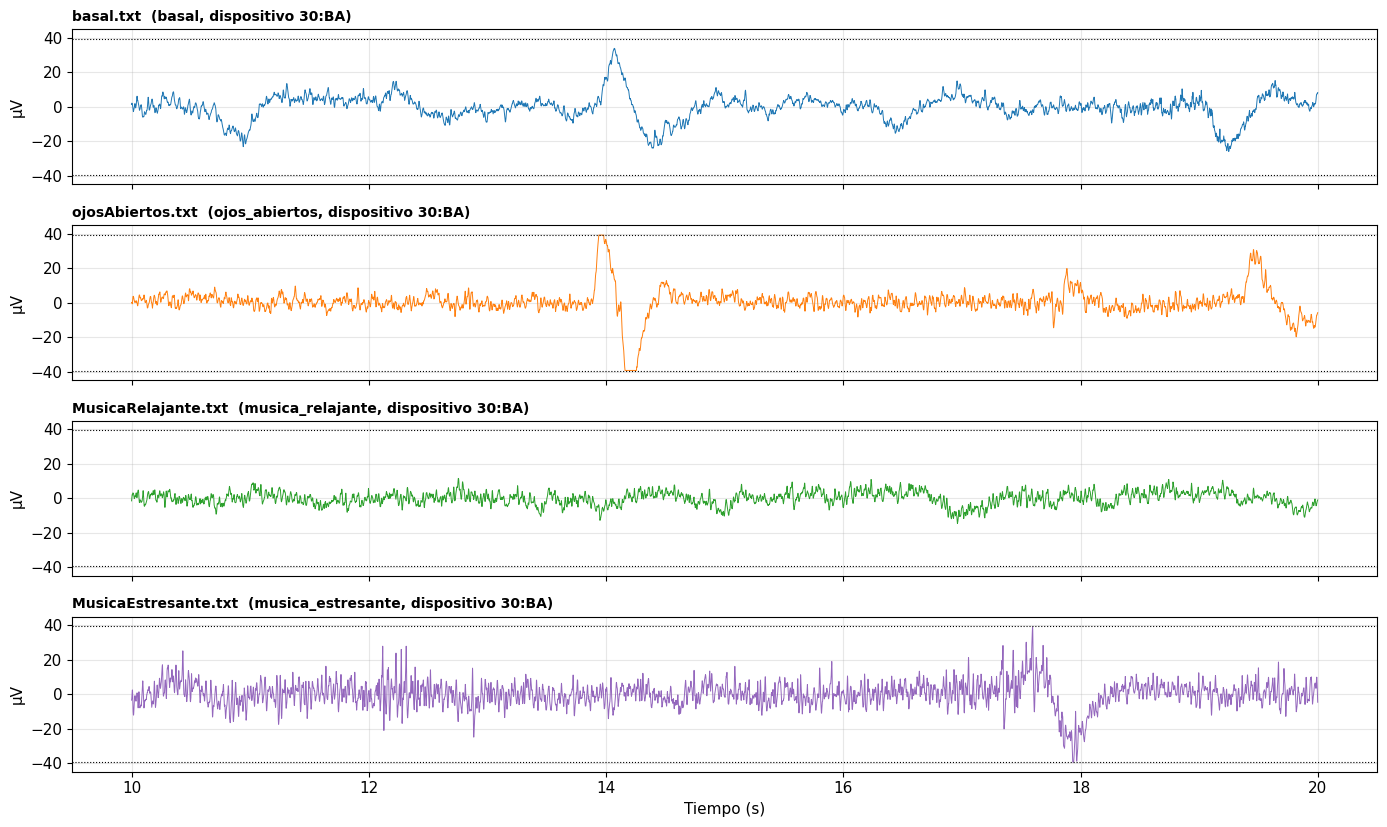

In [5]:
RANGO_UV = 0.5 * 3.3 / 41782 * 1e6      # ±39.5 µV
T0, DUR = 10, 10
fig, ax = plt.subplots(len(inventario), 1, figsize=(14, 2.1 * len(inventario)), sharex=True, squeeze=False)
for a, (_, fila) in zip(ax[:, 0], tabla_lectura.iterrows()):
    r = senales[fila.archivo]
    t = np.arange(len(r["eeg_uV"])) / FS
    sl = (t >= T0) & (t < T0 + DUR)
    a.plot(t[sl], r["eeg_uV"][sl] - np.mean(r["eeg_uV"]), color=COLOR.get(fila["condición"], "gray"), lw=0.7)
    a.axhline(RANGO_UV, color="k", ls=":", lw=0.8); a.axhline(-RANGO_UV, color="k", ls=":", lw=0.8)
    a.set_ylim(-45, 45); a.set_ylabel("µV")
    a.set_title(f"{fila.archivo}  ({fila['condición']}, dispositivo {fila.dispositivo})", loc="left", fontsize=10)
ax[-1, 0].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### ✍️ Pregunta A.2
1. ¿Qué registros tienen **mayor amplitud**? ¿Cuáles tocan el rango del sensor?
2. En `parpadeo_masticacion`, ¿distingues ondas lentas grandes (parpadeos) y tramos rápidos (masticación)?

✅ **Respuesta A.2**

1. Ordenados aproximadamente de menor a mayor amplitud:
   - **Música relajante:** oscilaciones pequeñas, generalmente dentro de ±10 µV.
   - **Basal:** oscilaciones moderadas, con picos de hasta ~+35 µV y −25 µV.
   - **Música estresante:** oscilaciones más rápidas, con picos de hasta ~±40 µV.
   - **Ojos abiertos:** presenta las mayores variaciones, alcanzando los límites del sensor (±39.5 µV).

   Los registros de ojos abiertos y música estresante presentan las mayores amplitudes. Sin embargo, solo ojos abiertos muestra saturación considerable (3.35 %), mientras que música estresante presenta una saturación mínima (0.10 %).

2. **No se cuenta con el registro de `parpadeo_masticacion`.** Sin embargo, en `ojos_abiertos` se observan ondas lentas y grandes que llegan al límite del sensor, compatibles con posibles artefactos oculares. También se observan oscilaciones rápidas superpuestas, aunque no es posible atribuirlas específicamente a la masticación.

<a id="A4"></a>
## A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?

Calculamos la **densidad espectral de potencia (PSD)** con el **método de Welch**, tal como en la clase:
1. Dividir la señal en segmentos superpuestos.
2. Aplicar una ventana a cada segmento.
3. Calcular la FFT de cada segmento → periodograma.
4. **Promediar** los periodogramas. Así se obtiene una estimación mucho más estable que con una sola FFT.

### 📖 Aliasing: cuando una frecuencia se "disfraza" de otra
Con **Fs = 100 Hz** solo podemos representar frecuencias hasta **50 Hz** (Nyquist). Una señal de **60 Hz**, como la de la red eléctrica, **no desaparece**: se "pliega" y aparece en otra frecuencia:

$$
f_{alias} = |f - k \cdot F_s| = |60 - 1 \cdot 100| = \mathbf{40\ Hz}
$$

> 💡 **Analogía:** es el efecto de las ruedas de un auto que en un video parecen girar lento o al revés. La cámara toma pocas fotos por segundo y "engaña" sobre la velocidad real.

Si vemos un pico angosto en **40 Hz**, es muy probable que sea **la red eléctrica disfrazada**, no actividad gamma del cerebro.

### 📖 Ritmo cerebral vs. "línea" de interferencia
Un ritmo cerebral (por ejemplo, la alfa) aparece en el espectro como una **"loma" ancha**, de 1 a 3 Hz de ancho, porque su frecuencia fluctúa. Una **interferencia** (red eléctrica, equipos cercanos, la propia electrónica) aparece como una **"línea" muy angosta y muy alta**: ocupa una sola frecuencia y sobresale cientos de veces sobre sus vecinas.

El cuaderno busca automáticamente **líneas angostas**: picos que sobresalen **más de 100 veces** sobre su entorno (con resolución de 0.05 Hz) y que concentran **al menos el 4 %** de la potencia de 1–45 Hz.

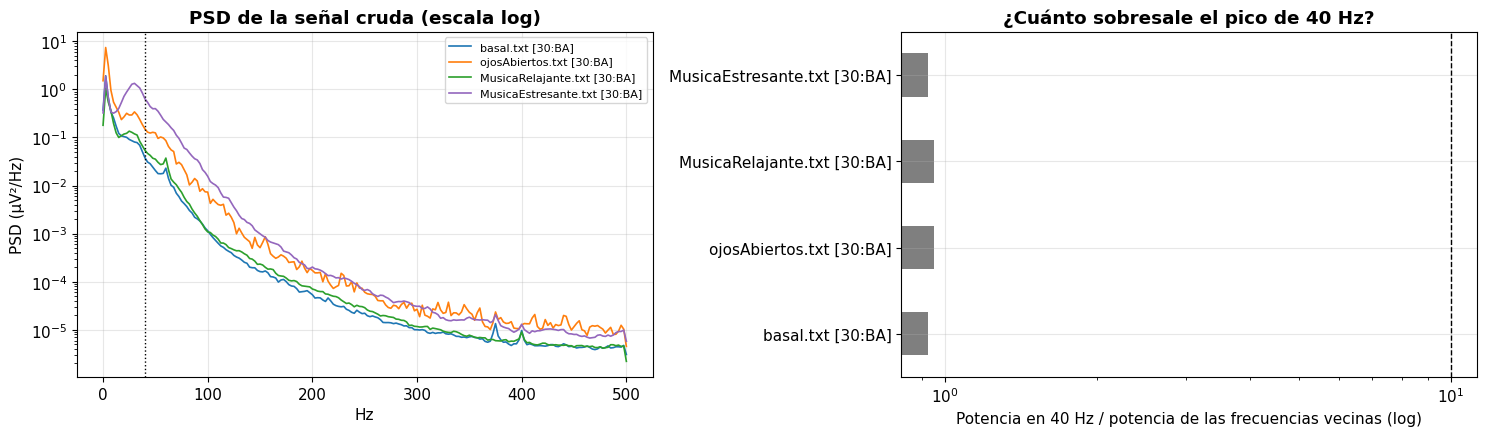

,pico en 40 Hz (veces)
basal.txt [30:BA],0.9
ojosAbiertos.txt [30:BA],1.0
MusicaRelajante.txt [30:BA],1.0
MusicaEstresante.txt [30:BA],0.9


,archivo,dispositivo,líneas angostas (Hz → % de la potencia)
0,basal.txt,30:BA,ninguna
1,ojosAbiertos.txt,30:BA,ninguna
2,MusicaRelajante.txt,30:BA,ninguna
3,MusicaEstresante.txt,30:BA,ninguna


In [6]:
def psd(x, fs=FS, nperseg=400):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=min(nperseg, len(x)))

def pico_relativo(f, P, f0=40, ancho=2):
    vecinos = P[(np.abs(f - f0) > ancho) & (np.abs(f - f0) < 6)]
    return P[np.argmin(np.abs(f - f0))] / np.median(vecinos)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
dispositivos = tabla_lectura["dispositivo"].unique()
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    f, P = psd(r["eeg_uV"][~r["saturada"]] if r["saturada"].mean() < 0.5 else r["eeg_uV"])
    estilo = "-" if fila.dispositivo == dispositivos[0] else "--"
    ax[0].semilogy(f, P, estilo, color=COLOR.get(fila["condición"], "gray"), lw=1.2, label=f"{fila.archivo} [{fila.dispositivo}]")
    r["pico40"] = pico_relativo(f, P)
ax[0].axvline(40, color="k", ls=":", lw=1)
ax[0].set_xlabel("Hz"); ax[0].set_ylabel("PSD (µV²/Hz)"); ax[0].set_title("PSD de la señal cruda (escala log)")
ax[0].legend(fontsize=8)
picos = pd.Series({f"{a} [{senales[a]['dispositivo']}]": senales[a]["pico40"] for a in tabla_lectura.archivo})
picos.plot.barh(ax=ax[1], color=["tab:gray" if senales[a]["dispositivo"] == dispositivos[0] else "tab:red"
                                 for a in tabla_lectura.archivo], log=True)
ax[1].axvline(10, color="k", ls="--", lw=1)
ax[1].set_xlabel("Potencia en 40 Hz / potencia de las frecuencias vecinas (log)")
ax[1].set_title("¿Cuánto sobresale el pico de 40 Hz?")
plt.tight_layout(); plt.show()
display(picos.round(1).rename("pico en 40 Hz (veces)").to_frame())

def lineas_angostas(x, fs=FS, prominencia_log=2.0, fraccion_min=0.04):
    # Picos espectrales muy angostos (interferencias): >100 veces sobre su entorno y >= 4 % de la potencia
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(20 * fs, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    picos_idx, props = signal.find_peaks(np.log10(P), prominence=prominencia_log)
    lineas = []
    for p in picos_idx:
        fraccion = P[max(0, p - 2): p + 3].sum() / total
        if 1.5 <= f[p] <= 48 and fraccion >= fraccion_min:
            lineas.append((round(float(f[p]), 2), round(100 * fraccion, 1)))
    return lineas

i_rec = 4 * FS   # se ignoran los primeros 4 s (ver A.6)
filas = []
for a in tabla_lectura.archivo:
    r = senales[a]
    r["lineas_detectadas"] = lineas_angostas(r["eeg_uV"][i_rec:])
    filas.append({"archivo": a, "dispositivo": r["dispositivo"],
                  "líneas angostas (Hz → % de la potencia)": ", ".join(f"{fr} Hz → {pc} %" for fr, pc in r["lineas_detectadas"]) or "ninguna"})
display(pd.DataFrame(filas))

### ✍️ Pregunta A.3
1. ¿Qué archivos tienen un pico grande en 40 Hz? ¿Tienen algo en común (mira el **dispositivo**)?
2. Según la fórmula de aliasing, ¿de dónde viene ese pico? ¿Qué filtro *notch* deberíamos usar: 60 Hz o 40 Hz?
3. ¿Qué **otras líneas angostas** encontró el detector? ¿En qué dispositivo? ¿Caen dentro de alguna banda cerebral? ¿Qué pasaría con la potencia de esa banda si no las quitamos?

✅ **Respuesta A.3**

1. **Pico grande en 40 Hz:** Ninguno de los cuatro archivos presenta un pico significativo en 40 Hz. Los valores son basal (0.9 veces), ojos abiertos (1.0), música relajante (1.0) y música estresante (0.9). **Todos son del mismo dispositivo 30:BA.**

2. Con **Fs = 1000 Hz**, la frecuencia de Nyquist es 500 Hz. Por lo tanto, la interferencia de la red eléctrica de 60 Hz no produce aliasing en 40 Hz, ya que se encuentra por debajo de Nyquist. Si se detectara interferencia de la red eléctrica de 60 Hz, correspondería utilizar un **notch en 60 Hz**, no en 40 Hz. Sin embargo, nuestros registros no presentan un pico significativo en 40 Hz.

3. **Otras líneas angostas:** El detector no encontró ninguna línea angosta significativa en los cuatro registros del dispositivo **30:BA**. Por lo tanto, no se identificaron interferencias estrechas dentro de las bandas cerebrales. Si existieran y no se eliminaran, podrían aumentar artificialmente la potencia de la banda correspondiente y alterar su interpretación.

<a id="A5"></a>
## A.5 Control de calidad automático

Resumimos la calidad de cada archivo con un **semáforo**:

| Estado | Criterio |
|---|---|
| ✅ Bueno | Sin saturación, sin pico en 40 Hz (< 10 veces sus vecinos) y sin otras líneas angostas |
| ⚠️ Revisar | Saturación < 1 %, pico de 40 Hz ≥ 10 veces **o** líneas angostas (interferencias que un filtro puede quitar) |
| ❌ Problemático | Saturación ≥ 1 % de las muestras |

También calculamos la **curtosis** de la señal. Una curtosis alta indica **eventos aislados muy grandes** (parpadeos, movimientos, saltos), típicos de artefactos.

In [7]:
filas = []
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    pct = 100 * r["saturada"].mean()
    otras = [fr for fr, _ in r["lineas_detectadas"] if abs(fr - 40) > 1]
    estado = "❌" if pct >= 1 else ("⚠️" if (pct > 0 or r["pico40"] >= 10 or otras) else "✅")
    x = r["eeg_uV"] - np.mean(r["eeg_uV"])
    filas.append({"archivo": fila.archivo, "condición": fila["condición"], "dispositivo": fila.dispositivo,
                  "% saturado": round(pct, 2), "pico 40 Hz (veces)": round(r["pico40"], 1),
                  "otras líneas (Hz)": ", ".join(map(str, otras)) or "-",
                  "desv. estándar (µV)": round(np.std(x), 2), "curtosis": round(kurtosis(x), 1),
                  "estado": estado})
calidad = pd.DataFrame(filas)
display(calidad)

,archivo,condición,dispositivo,% saturado,pico 40 Hz (veces),otras líneas (Hz),desv. estándar (µV),curtosis,estado
0,basal.txt,basal,30:BA,0.00,0.9,-,5.13,5.8,✅
1,ojosAbiertos.txt,ojos_abiertos,30:BA,3.35,1.0,-,10.72,5.9,❌
2,MusicaRelajante.txt,musica_relajante,30:BA,0.00,1.0,-,4.57,0.4,✅
3,MusicaEstresante.txt,musica_estresante,30:BA,0.10,0.9,-,8.24,1.7,⚠️


### ✍️ Pregunta A.4
1. ¿Qué archivos quedaron en ❌ y en ⚠️? ¿Por qué motivo cada uno?
2. ¿Qué archivo tiene la curtosis más alta? Relaciónalo con la columna *segundos con saturación* de A.2.

✅ **Respuesta A.4**

1. **❌ (saturación ≥ 1 %):**
   - `ojos_abiertos` (3.35 %).

   **⚠️ (saturación leve):**
   - `musica_estresante` (0.10 %).

   **✅ (sin problemas de calidad detectados):**
   - `basal` (0 % de saturación).
   - `musica_relajante` (0 % de saturación).

   Ninguno de los cuatro registros presenta interferencias significativas en 40 Hz ni otras líneas angostas detectadas.

2. **`ojos_abiertos` tiene la curtosis más alta (5.9)**, seguida de `basal` (5.8). Esto se relaciona con la saturación observada en `ojos_abiertos` (3.35 %), distribuida en distintos momentos del registro. Los valores extremos y los artefactos pueden aumentar la curtosis. Por ello, se deben identificar y rechazar las épocas saturadas antes del análisis.

<a id="A6"></a>
## A.6 Conclusiones de la Parte A: decisiones para el procesamiento

La revisión de los datos nos lleva a **cuatro decisiones** que aplicaremos en la Parte B. Ajústalas si tus datos lo requieren:

| Parámetro | Valor por defecto | ¿Por qué? |
|---|---|---|
| `RECORTE_INICIO_S` | 4 s | Al iniciar la adquisición, el amplificador tarda unos segundos en estabilizarse |
| `NOTCH_HZ` | 40 Hz | Es el **alias** de la red eléctrica de 60 Hz cuando Fs = 100 Hz |
| `QUITAR_LINEAS` | `True` | Aplica un notch angosto en cada **línea de interferencia** detectada en A.4, en su propio archivo |
| Rechazo de épocas | Toda época con al menos una muestra saturada | La saturación destruye información que ningún filtro puede recuperar |

### ✍️ Pregunta A.5
Escribe en 3 a 4 líneas tus conclusiones sobre la calidad de tus datos. ¿Hay algún archivo que no usarías? ¿Por qué podría ser un problema que se hayan usado **dos dispositivos distintos**?

✅ **Respuesta A.5 — Conclusiones de la Parte A**

Los cuatro registros son utilizables, pero algunos requieren mayor cuidado durante el procesamiento:

- **Recortar los primeros 4 s:** para descartar posibles inestabilidades al inicio de la adquisición.
- **Filtrar las interferencias:** no se detectaron picos significativos en 40 Hz ni otras líneas angostas. Por ello, no es necesario aplicar un notch de 40 Hz.
- **Rechazar las épocas saturadas:** afecta principalmente a ojos_abiertos (3.35 %) y, en menor medida, a música_estresante (0.10 %).

**Dispositivos:** Todas las señales fueron registradas con el mismo BITalino (30:BA), por lo que no existe el problema de comparar condiciones grabadas con dispositivos diferentes. Sin embargo, las diferencias de calidad entre registros podrían influir en los resultados.

In [9]:

# =================== ✍️ DECISIONES ===================
RECORTE_INICIO_S = 4
NOTCH_HZ = None
QUITAR_LINEAS = True
# ======================================================
print(f"Recorte inicial: {RECORTE_INICIO_S} s | Notch: {NOTCH_HZ} Hz | Quitar líneas angostas: {QUITAR_LINEAS}")


Recorte inicial: 4 s | Notch: None Hz | Quitar líneas angostas: True


---
<a id="parteB"></a>
# 🅱️ PARTE B — Tratamiento y extracción de características *(≈ 40 min)*

[⬆️ Volver al índice](#indice)

<a id="B1"></a>
## B.1 El pipeline de procesamiento

Este es el camino que recorrerá cada registro, siguiendo el esquema de la clase:

| Paso | Etapa | Qué hace | Sección |
|---|---|---|---|
| 1 | **Filtrado** | Quita la deriva lenta, el ruido de alta frecuencia y la red eléctrica (40 Hz) | B.2 |
| 2 | **Análisis de ritmos** | Mide cuánta potencia hay en delta, theta, alfa, beta y gamma | B.3 |
| 3 | **Limpieza con ICA** | Separa y elimina componentes de artefactos (parpadeos, interferencia) | B.4 |
| 4 | **Preprocesamiento** | Normalización (z-score) y corte en épocas de 2 s; se rechazan las saturadas | B.5 |
| 5 | **Extracción de características** | ~22 números por época | B.6 |
| 6 | **Ingeniería de características** | Cocientes entre bandas, logaritmos, tabla final | B.6–B.7 |
| 7 | **Clasificación** | ¿Podemos reconocer la condición a partir de las características? | B.8 |

<a id="B2"></a>
## B.2 Filtrado

| Filtro | Configuración | ¿Por qué? |
|---|---|---|
| **Pasa-banda Butterworth** | 1 – 45 Hz, orden 4 | Quita la deriva lenta (< 1 Hz) y se queda por debajo de Nyquist (50 Hz). El ejemplo de MNE también recomienda un pasa-altos de 1 Hz antes de aplicar ICA |
| **Notch** | 40 Hz (Q = 20) | Elimina el **alias de la red eléctrica** encontrado en A.4 |
| **Notch angostos** | En cada línea detectada en A.4 (Q = 30, ~0.15–0.8 Hz de ancho) | Elimina las otras interferencias sin borrar la banda cerebral donde caen |

Se filtra "ida y vuelta" (`filtfilt`) para no desfasar la señal. Veamos el efecto en el archivo con **más interferencia**.

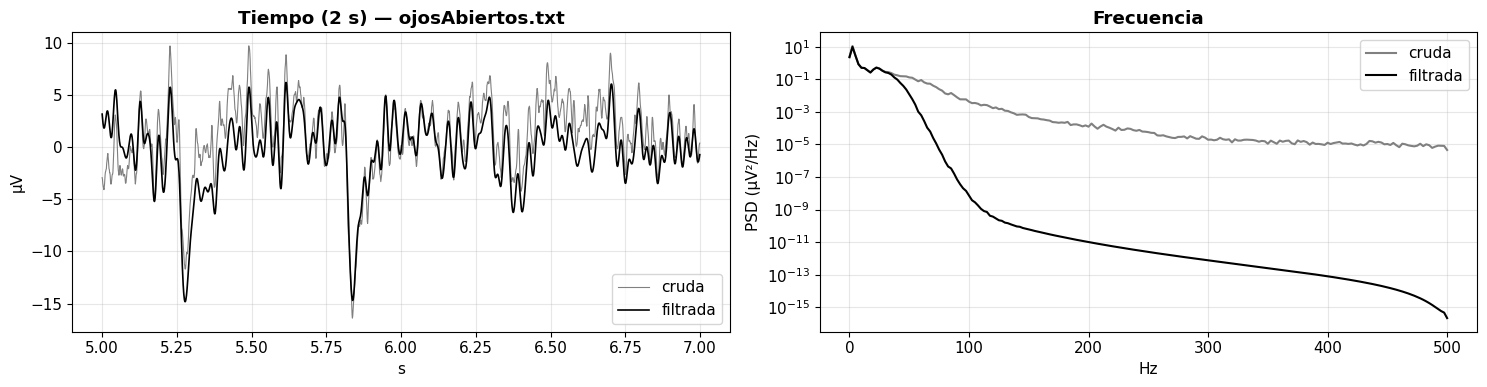

In [11]:
def filtrar_eeg(x, fs=FS, notch=NOTCH_HZ, lineas=()):
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if notch and notch < fs / 2:
        b, a = signal.iirnotch(notch, 20, fs=fs)
        y = signal.filtfilt(b, a, y)
    elif notch:
        print(f"⚠️ Notch de {notch} Hz imposible: está por encima de Nyquist ({fs/2:.0f} Hz). No se aplicó.")
    for f0 in lineas:                       # notch angosto en cada línea de interferencia
        if notch is None or abs(f0 - notch) > 1:
            b, a = signal.iirnotch(f0, 30, fs=fs)
            y = signal.filtfilt(b, a, y)
    return y

def lineas_de(archivo, quitar=QUITAR_LINEAS):
    return [fr for fr, _ in senales[archivo]["lineas_detectadas"]] if quitar else []

i0 = int(RECORTE_INICIO_S * FS)
peor = max(senales, key=lambda a: senales[a]["pico40"])
x_crudo = senales[peor]["eeg_uV"][i0:] - np.mean(senales[peor]["eeg_uV"][i0:])
x_filt = filtrar_eeg(senales[peor]["eeg_uV"][i0:], lineas=lineas_de(peor))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
t = np.arange(len(x_crudo)) / FS
sl = (t >= 5) & (t < 7)
ax[0].plot(t[sl], x_crudo[sl], color="gray", lw=0.8, label="cruda")
ax[0].plot(t[sl], x_filt[sl], color="black", lw=1.2, label="filtrada")
ax[0].set_title(f"Tiempo (2 s) — {peor}"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x_crudo, "cruda", "gray"), (x_filt, "filtrada", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].set_xlabel("Hz"); ax[1].set_ylabel("PSD (µV²/Hz)"); ax[1].set_title("Frecuencia"); ax[1].legend()
plt.tight_layout(); plt.show()

🔎 **Observa**

- **En la frecuencia:** la potencia por debajo de 1 Hz disminuye y las frecuencias altas se atenúan considerablemente, especialmente por encima de 40 Hz. No se observa un pico significativo en 40 Hz en la señal cruda, por lo que no corresponde afirmar que desapareció una interferencia en esa frecuencia.

- **En el tiempo:** la señal cruda presenta oscilaciones rápidas superpuestas; la filtrada queda más suave y limpia, conservando las variaciones principales de la señal. Sin embargo, todavía se observan picos pronunciados que podrían corresponder a artefactos.

<a id="B3"></a>
## B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma

### 📖 Dos formas de "ver" las bandas
1. **En el tiempo:** filtramos la señal en cada banda y vemos cómo oscila cada "sección de la orquesta".
2. **En la frecuencia:** integramos la PSD de Welch dentro de cada banda para obtener la **potencia de banda**:
   - **Absoluta** (µV²): cuánta energía hay en la banda.
   - **Relativa** (%): qué fracción del total (1–45 Hz) corresponde a esa banda. Es más fácil de comparar entre registros y dispositivos.

> ⚠️ **Gamma en estos datos:** con Fs = 100 Hz solo vemos gamma entre 30 y 45 Hz, y el notch quita 38–42 Hz. La gamma de superficie, además, suele estar dominada por **actividad muscular**. Hay que interpretarla con mucha cautela.

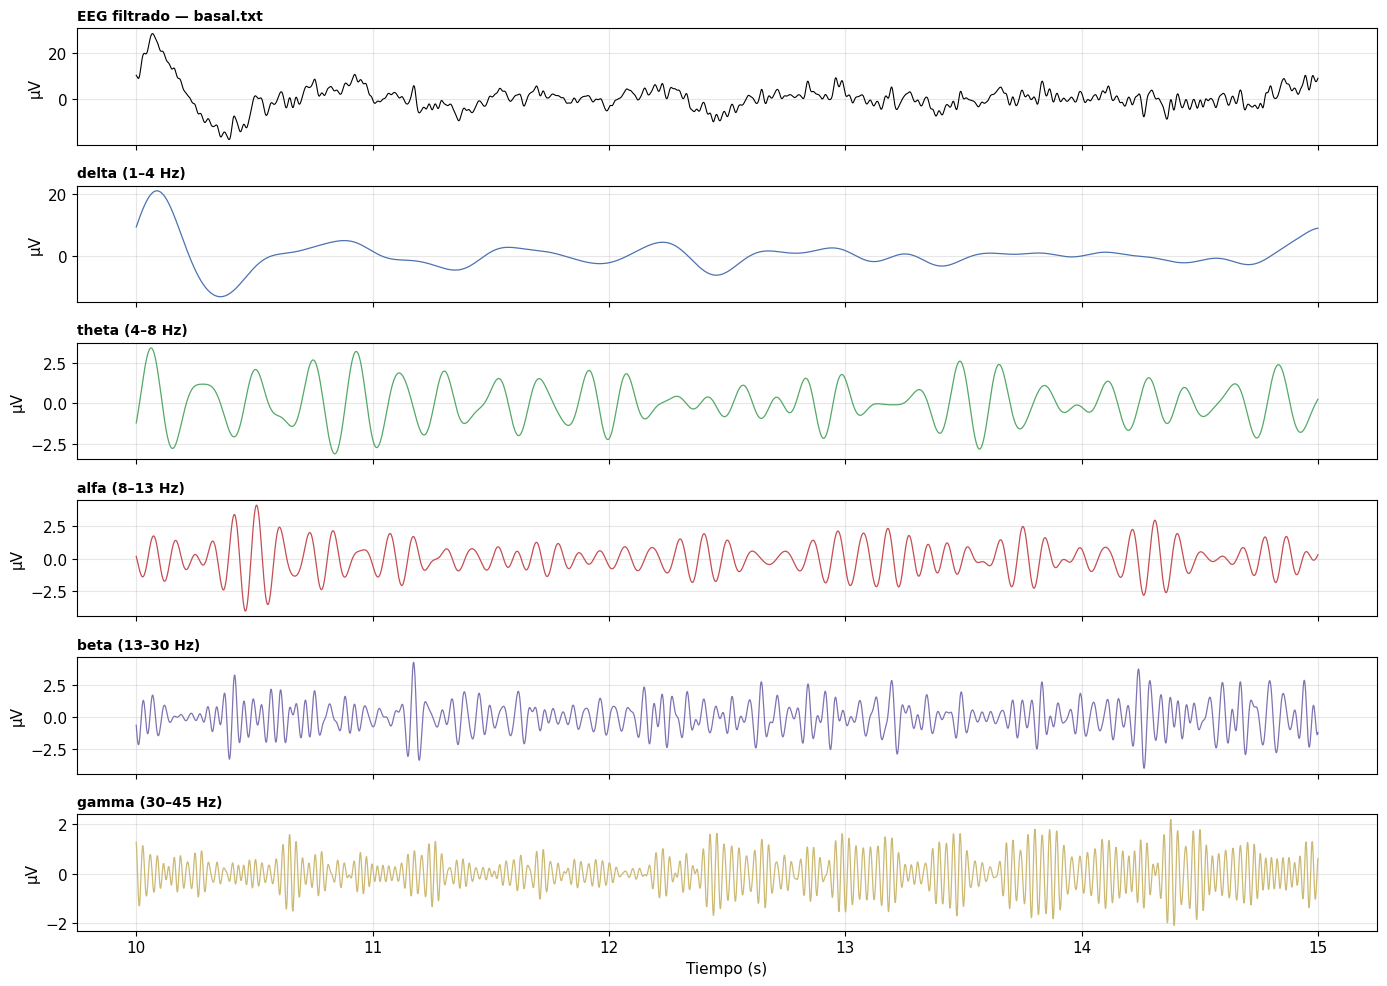

In [12]:
for a, r in senales.items():
    r["filtrada"] = filtrar_eeg(r["eeg_uV"][i0:], lineas=lineas_de(a))
    r["sat_rec"] = r["saturada"][i0:]

# 1) Bandas en el tiempo para el registro basal más limpio
basales = [a for a in calidad[calidad["condición"] == "basal"].sort_values("pico 40 Hz (veces)").archivo]
ref = basales[0] if basales else list(senales)[0]
x = senales[ref]["filtrada"]; t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 15)
fig, ax = plt.subplots(6, 1, figsize=(14, 10), sharex=True)
ax[0].plot(t[sl], x[sl], color="black", lw=0.8); ax[0].set_title(f"EEG filtrado — {ref}", loc="left", fontsize=10)
for a, (b, (lo, hi)) in zip(ax[1:], BANDAS.items()):
    sos = signal.butter(4, [lo, hi], btype="bandpass", fs=FS, output="sos")
    a.plot(t[sl], signal.sosfiltfilt(sos, x)[sl], color=COLOR_BANDA[b], lw=0.9)
    a.set_title(f"{b} ({lo}–{hi} Hz)", loc="left", fontsize=10)
for a in ax: a.set_ylabel("µV")
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

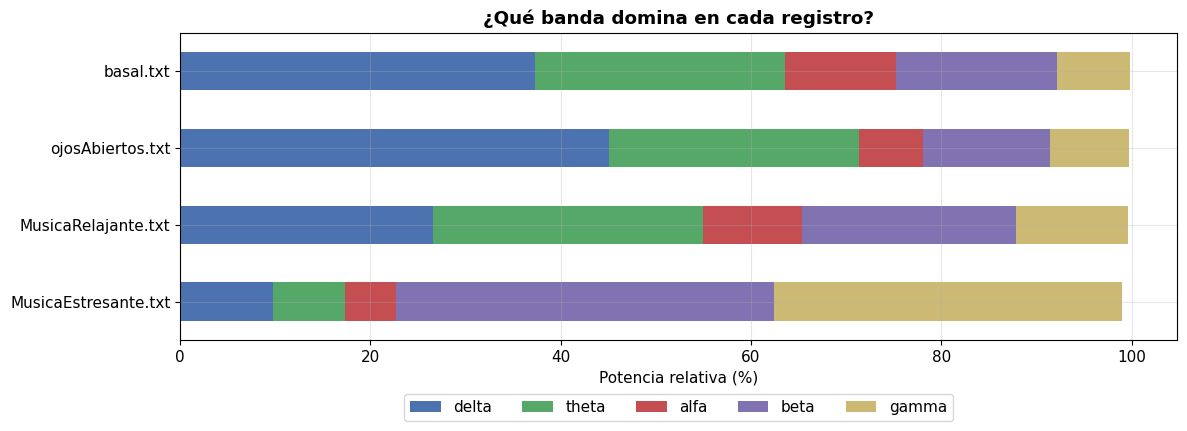

,delta,theta,alfa,beta,gamma
basal.txt,37.3,26.3,11.7,16.9,7.6
ojosAbiertos.txt,45.1,26.3,6.7,13.3,8.3
MusicaRelajante.txt,26.6,28.4,10.3,22.5,11.8
MusicaEstresante.txt,9.8,7.5,5.4,39.8,36.5


In [13]:
# 2) Potencia relativa por banda en cada registro (PSD de Welch sobre la señal filtrada, sin muestras saturadas)
def potencia_bandas(x, fs=FS):
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(400, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    return {b: P[(f >= lo) & (f < hi)].sum() / total for b, (lo, hi) in BANDAS.items()}

pot = pd.DataFrame({a: potencia_bandas(r["filtrada"][~r["sat_rec"]]) for a, r in senales.items()}).T * 100
pot = pot.loc[tabla_lectura.archivo]
ax = pot.plot.barh(stacked=True, figsize=(12, 4.5), color=[COLOR_BANDA[b] for b in BANDAS])
ax.set_xlabel("Potencia relativa (%)"); ax.set_title("¿Qué banda domina en cada registro?"); ax.invert_yaxis()
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15)); plt.tight_layout(); plt.show()
display(pot.round(1))

### ✍️ Pregunta B.1
1. ¿Qué banda domina en los registros **basales** (ojos cerrados)? ¿Es la alfa, como se esperaría?
2. Compara `Basal1` con `ojos_abiertos`. ¿Disminuye la alfa al abrir los ojos? ¿Qué banda cambia más?
3. *(Para pensar)* Los electrodos están en **Fp1/Fp2** (frente). La alfa de reposo es más fuerte en la zona **occipital** (nuca). ¿Cómo influye esto en lo que ves?

✅ **Respuesta B.1** (potencia relativa de cada registro, tras el filtrado)

1. **La alfa no domina** en el registro basal:
   - **Basal:** delta 37.3 %, theta 26.3 %, beta 16.9 %, alfa 11.7 % y gamma 7.6 %.

   La banda dominante es **delta (37.3 %)**, seguida de theta (26.3 %). No se observa el patrón clásico de «alfa dominante con ojos cerrados».

2. **Sí disminuye.** La alfa de ojos_abiertos (6.7 %) es menor que la del basal (11.7 %), por lo que se observa una reducción de la potencia alfa al abrir los ojos, compatible con el **bloqueo alfa**. Lo que más cambia entre basal y ojos_abiertos es la **delta**, que sube de 37.3 % a 45.1 %. La alfa disminuye 5 puntos porcentuales, mientras que theta permanece igual (26.3 %).

3. *(Conceptual)* La alfa de reposo se genera sobre todo en la corteza **occipital y parietal**. Un electrodo bipolar entre **Fp1 y Fp2** (frente) está lejos de esa zona y, además, resta dos puntos casi simétricos, lo que atenúa la actividad común a ambos. Por eso la alfa se ve poco, y la región frontal es más sensible a los movimientos oculares y a los músculos de la frente.

<a id="B4"></a>
## B.4 Filtro ICA: separar el cerebro de los artefactos

### B.4.1 📖 Definición fácil: el problema de la fiesta (*cocktail party*)
Imagina una fiesta con **3 personas hablando** y **3 micrófonos** en distintos lugares. Cada micrófono graba una **mezcla** de las tres voces. El **Análisis de Componentes Independientes (ICA)** es un algoritmo que, solo con las grabaciones de los micrófonos, **recupera cada voz por separado**.

En el EEG:
- Los **micrófonos** son los electrodos.
- Las **voces** son las fuentes: actividad cerebral, parpadeos, músculos, red eléctrica.

Si separamos las fuentes, podemos **apagar las de artefactos** y reconstruir una señal limpia.

### En términos matemáticos

$$
\underbrace{\mathbf{X}}_{\text{electrodos}} = \underbrace{\mathbf{A}}_{\text{mezcla}} \cdot \underbrace{\mathbf{S}}_{\text{fuentes}}
\qquad\Longrightarrow\qquad
\hat{\mathbf{S}} = \mathbf{W}\,\mathbf{X}, \quad \mathbf{W} \approx \mathbf{A}^{-1}
$$

ICA estima la matriz de "desmezcla" **W** suponiendo que:
1. Las fuentes son **estadísticamente independientes**.
2. Las fuentes **no son gaussianas**. El algoritmo FastICA busca justamente las direcciones más "no gaussianas".
3. Hay **al menos tantos canales como fuentes** que queremos separar.

**Limpieza en 3 pasos:** (1) descomponer en componentes; (2) **identificar** las de artefactos; (3) ponerlas en cero y **reconstruir**.

### B.4.2 Demostración con señales simuladas
Antes de usar datos reales, probamos ICA en un caso donde **conocemos la respuesta**: 3 fuentes (alfa de 10 Hz, parpadeos y ráfagas musculares) mezcladas en 3 "electrodos".

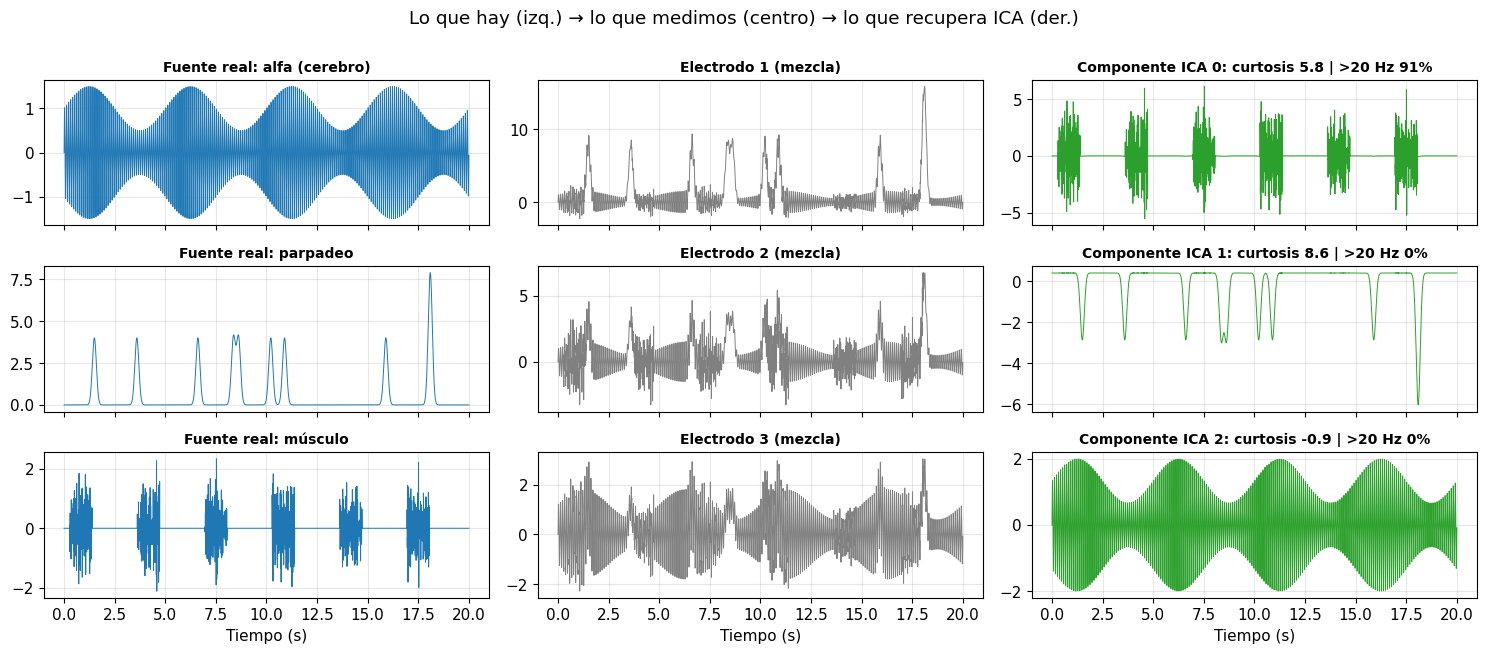

In [14]:
rng = np.random.default_rng(1)
ts = np.arange(0, 20, 1/FS)
alfa = np.sin(2*np.pi*10*ts) * (1 + 0.5*np.sin(2*np.pi*0.2*ts))                 # fuente cerebral
parpadeo = sum(np.exp(-((ts - tp)**2) / (2*0.1**2)) for tp in rng.uniform(1, 19, 10)) * 4  # fuente ocular
b, a_ = signal.butter(4, [20, 45], "bandpass", fs=FS)
musculo = (np.sin(2*np.pi*0.3*ts) > 0.5) * signal.lfilter(b, a_, rng.standard_normal(len(ts))) * 3  # fuente muscular
S_real = np.c_[alfa, parpadeo, musculo]
A_mezcla = np.array([[1.0, 2.0, 0.6],     # electrodo 1 (frontal: mucho parpadeo)
                     [1.0, 0.8, 1.2],     # electrodo 2
                     [1.2, 0.3, 0.4]])    # electrodo 3
X = S_real @ A_mezcla.T

ica_demo = FastICA(n_components=3, whiten="unit-variance", random_state=0)
S_est = ica_demo.fit_transform(X)

def metricas_componente(s, fs=FS):
    f, P = signal.welch(s, fs=fs, nperseg=min(256, len(s)))
    tot = P[f >= 1].sum()
    return {"curtosis": kurtosis(s), "fracción > 20 Hz": P[f >= 20].sum() / tot,
            "fracción 38–42 Hz": P[(f >= 38) & (f <= 42)].sum() / tot}

fig, ax = plt.subplots(3, 3, figsize=(15, 6.5), sharex=True)
nombres = ["alfa (cerebro)", "parpadeo", "músculo"]
for k in range(3):
    ax[k, 0].plot(ts, S_real[:, k], lw=0.7); ax[k, 0].set_title(f"Fuente real: {nombres[k]}", fontsize=10)
    ax[k, 1].plot(ts, X[:, k], lw=0.7, color="gray"); ax[k, 1].set_title(f"Electrodo {k+1} (mezcla)", fontsize=10)
    m = metricas_componente(S_est[:, k])
    ax[k, 2].plot(ts, S_est[:, k], lw=0.7, color="tab:green")
    ax[k, 2].set_title(f"Componente ICA {k}: curtosis {m['curtosis']:.1f} | >20 Hz {m['fracción > 20 Hz']:.0%}", fontsize=10)
for a in ax[-1]: a.set_xlabel("Tiempo (s)")
plt.suptitle("Lo que hay (izq.) → lo que medimos (centro) → lo que recupera ICA (der.)", y=1.0)
plt.tight_layout(); plt.show()

### 🔎 Observa
- ICA recupera las tres fuentes a partir de las mezclas. El **orden** y el **signo** pueden cambiar: ICA no sabe cuál es cuál.
- Para **identificar** cada componente usamos dos métricas sencillas:
  - **Curtosis alta** → eventos aislados y grandes, como **parpadeos** o movimientos.
  - **Mucha potencia por encima de 20 Hz** → actividad **muscular**.

### B.4.3 ¿Cómo se hace en EEG multicanal? El ejemplo de MNE
El ejemplo [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) de **MNE-Python** aplica ICA a un EEG de 59 canales:
1. Aplica un **pasa-altos de 1 Hz** ("ICA funciona mejor con un pasa-altos").
2. Ajusta un ICA de **15 componentes**.
3. Marca como **musculares** las componentes que cumplen los criterios de Dharmaprani et al. (2016):
   - **pendiente positiva** del espectro en escala log-log entre 7 y 75 Hz;
   - foco **periférico** en el mapa topográfico (lejos del vértex);
   - **un solo foco**, poco "suave" espacialmente;
   - y, además, una serie temporal "peluda", con picos como de EMG.
4. Compara la selección manual con la automática `ica.find_bads_muscle(raw)`.

```python
# Esquema del ejemplo de MNE (EEG multicanal; no se ejecuta en este cuaderno)
import mne
raw.filter(l_freq=1.0, h_freq=None)
ica = mne.preprocessing.ICA(n_components=15, method="picard", max_iter="auto", rng=97)
ica.fit(raw)
muscle_idx_auto, scores = ica.find_bads_muscle(raw)
ica.apply(raw, exclude=muscle_idx_auto)
```

> ⚠️ **Nuestro problema:** BITalino nos da **un solo canal**, e ICA necesita **al menos tantos canales como fuentes**. Además, sin varios electrodos no hay mapa topográfico, así que solo podemos usar los criterios **temporales y espectrales**.

### B.4.4 Solución para un canal: Wavelet-ICA
Una técnica usada en la literatura (Castellanos y Makarov, 2006) consiste en **fabricar "canales virtuales"** a partir del único canal:

1. Se descompone la señal con la **transformada wavelet** en **6 sub-bandas**. Es un análisis multirresolución: las sub-bandas **sumadas devuelven exactamente la señal original**.
2. Esas 6 sub-bandas se tratan como si fueran **6 electrodos**, y se aplica **FastICA**.
3. Se revisa cada componente:
   - **Más del 40 % de su potencia en 38–42 Hz** → es **interferencia de red** (alias). Se **elimina entera**. Solo aparece si no se usó el notch.
   - **Curtosis > 6** → contiene **transitorios** (parpadeos bruscos, movimientos, saltos). Se **corrige**: con una transformada wavelet se anulan solo los coeficientes **atípicamente grandes** (más de 4 desviaciones robustas). Es la idea del método WICA.
   - El resto se **conserva**.
4. Se vuelve a las sub-bandas y se **suman** para obtener la señal limpia.

> 💡 **¿Por qué corregir y no borrar?** En el EEG multicanal de MNE, una componente muscular es casi "pura" y se borra entera. Con un solo canal, cada componente mezcla un poco de cerebro y un poco de artefacto: si la borráramos entera, nos llevaríamos también una banda completa del EEG. Por eso solo "recortamos" la parte anómala.

Con Fs = 100 Hz y 6 niveles, las sub-bandas son aproximadamente:

| Sub-banda | Rango | Ritmo cercano |
|---|---|---|
| D1 | 25 – 50 Hz | gamma / beta alta |
| D2 | 12.5 – 25 Hz | beta |
| D3 | 6.25 – 12.5 Hz | alfa / theta alta |
| D4 | 3.1 – 6.25 Hz | theta |
| D5 | 1.6 – 3.1 Hz | delta |
| A5 | 0 – 1.6 Hz | muy lento (parpadeos, deriva) |

In [39]:
KURT_UMBRAL = 6       # curtosis por encima de la cual una componente contiene transitorios (artefactos)
LINEA_UMBRAL = 0.4    # fracción de potencia en 38–42 Hz por encima de la cual es interferencia de red
K_UMBRAL = 4          # umbral para "recortar" transitorios: coeficientes > K · desviación robusta

NOMBRES_SUBBANDA = ["D1 (250–500 Hz)", "D2 (125–250 Hz)", "D3 (62.5–125 Hz)", "D4 (31.25–62.5 Hz)", "D5 (15.6–31.25 Hz)", "A5 (0–15.6 Hz)"]

def subbandas_wavelet(x, nivel=5, wavelet="sym4"):
    # Análisis multirresolución (SWT): devuelve sub-bandas que SUMADAS reconstruyen x exactamente
    n = len(x); m = int(np.ceil(n / 2**nivel) * 2**nivel)
    xp = np.pad(x, (0, m - n), mode="reflect")
    comp = np.array(pywt.mra(xp, wavelet, level=nivel, transform="swt"))[:, :n]
    return comp[::-1]      # orden: D1 (rápida) ... A5 (lenta)

def quitar_transitorios(s, k=K_UMBRAL, wavelet="db4", nivel=4):
    # Corrección tipo WICA: en cada nivel wavelet se anulan SOLO los coeficientes atípicamente grandes
    coef = pywt.wavedec(s, wavelet, level=nivel)
    coef = [c * (np.abs(c) <= k * np.median(np.abs(c)) / 0.6745) for c in coef]
    return pywt.waverec(coef, wavelet)[:len(s)]

def ica_un_canal(x, kurt_umbral=KURT_UMBRAL, linea_umbral=LINEA_UMBRAL):
    V = subbandas_wavelet(x)                                     # (6, n): "canales virtuales"
    ica = FastICA(n_components=V.shape[0], whiten="unit-variance", random_state=0, max_iter=3000)
    S = ica.fit_transform(V.T)                                   # (n, 6): componentes independientes
    metr = pd.DataFrame([metricas_componente(S[:, k]) for k in range(S.shape[1])])
    aporte = [np.var(np.outer(S[:, k], ica.mixing_[:, k]).sum(axis=1)) / np.var(x) for k in range(S.shape[1])]
    metr["% varianza de la señal"] = 100 * np.array(aporte)
    metr["sub-banda dominante"] = [NOMBRES_SUBBANDA[j] for j in np.argmax(ica.mixing_**2, axis=0)]
    es_red = metr["fracción 38–42 Hz"] > linea_umbral
    es_trans = (metr["curtosis"] > kurt_umbral) & ~es_red
    metr["acción"] = np.where(es_red, "eliminar (red)", np.where(es_trans, "corregir (transitorios)", "conservar"))
    metr["artefacto"] = es_red | es_trans
    S_limpio = S.copy()
    for k in range(S.shape[1]):
        if es_red[k]:
            S_limpio[:, k] = 0                                   # componente de red: se elimina entera
        elif es_trans[k]:
            S_limpio[:, k] = quitar_transitorios(S[:, k])        # componente con transitorios: se corrige
    # Artefacto estimado = lo que se quitó, devuelto a sub-bandas y sumado
    artefacto = (ica.inverse_transform(S) - ica.inverse_transform(S_limpio)).sum(axis=1)
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=FS, output="sos")
    x_limpia = x - signal.sosfiltfilt(sos, artefacto)            # se resta solo dentro de la banda 1–45 Hz
    return x_limpia, {"V": V, "S": S, "S_limpio": S_limpio, "metricas": metr}
print("✅ Funciones de Wavelet-ICA listas.")

✅ Funciones de Wavelet-ICA listas.


### B.4.5 Wavelet-ICA paso a paso sobre el registro con artefactos
Aplicamos el método al registro de **parpadeo y masticación**, que contiene artefactos a propósito.

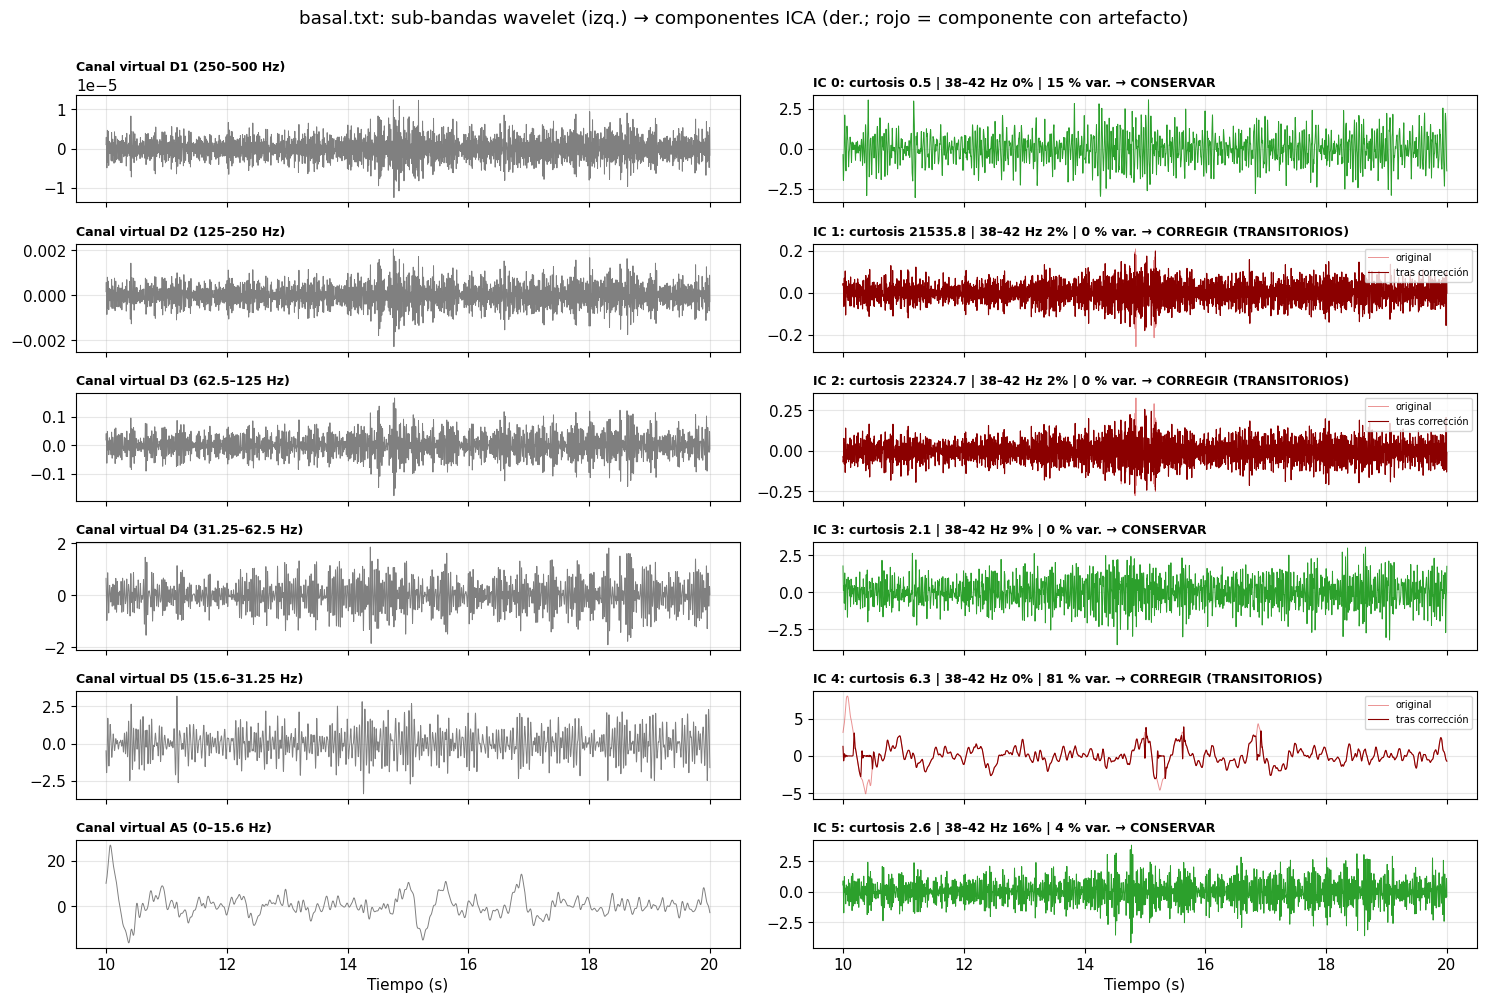

,curtosis,fracción > 20 Hz,fracción 38–42 Hz,% varianza de la señal,sub-banda dominante,acción,artefacto
0,0.488,0.628,0.004,14.588,D5 (15.6–31.25 Hz),conservar,False
1,21535.799,0.978,0.016,0.000,D1 (250–500 Hz),corregir (transitorios),True
2,22324.703,0.911,0.024,0.000,A5 (0–15.6 Hz),corregir (transitorios),True
3,2.086,0.824,0.094,0.008,D4 (31.25–62.5 Hz),conservar,False
4,6.344,0.009,0.000,81.015,A5 (0–15.6 Hz),corregir (transitorios),True
5,2.592,0.996,0.161,4.389,D4 (31.25–62.5 Hz),conservar,False


In [43]:
cand = [a for a in senales if condicion_desde_nombre(a) == "parpadeo_masticacion"]
ej = cand[0] if cand else list(senales)[0]
x = senales[ej]["filtrada"]
x_limpia, det = ica_un_canal(x)
t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 20)

fig, ax = plt.subplots(6, 2, figsize=(15, 10), sharex=True)
for k in range(6):
    ax[k, 0].plot(t[sl], det["V"][k][sl], color="gray", lw=0.7)
    ax[k, 0].set_title(f"Canal virtual {NOMBRES_SUBBANDA[k]}", loc="left", fontsize=9)
    m = det["metricas"].iloc[k]
    if m["artefacto"]:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:red", lw=0.7, alpha=0.5, label="original")
        ax[k, 1].plot(t[sl], det["S_limpio"][sl, k], color="darkred", lw=0.8, label="tras corrección")
        ax[k, 1].legend(loc="upper right", fontsize=7)
    else:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:green", lw=0.7)
    ax[k, 1].set_title(f"IC {k}: curtosis {m['curtosis']:.1f} | 38–42 Hz {m['fracción 38–42 Hz']:.0%} | "
                       f"{m['% varianza de la señal']:.0f} % var. → {m['acción'].upper()}", loc="left", fontsize=9)
ax[-1, 0].set_xlabel("Tiempo (s)"); ax[-1, 1].set_xlabel("Tiempo (s)")
plt.suptitle(f"{ej}: sub-bandas wavelet (izq.) → componentes ICA (der.; rojo = componente con artefacto)", y=1.0)
plt.tight_layout(); plt.show()
display(det["metricas"].round(3))

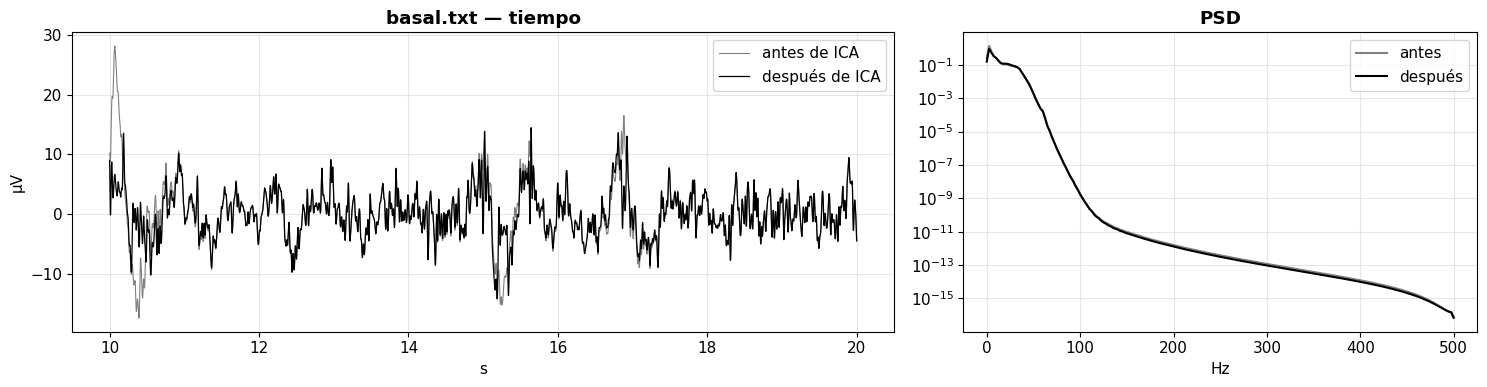

Varianza eliminada por ICA: 20.7 %


In [40]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(t[sl], x[sl], color="gray", lw=0.8, label="antes de ICA")
ax[0].plot(t[sl], x_limpia[sl], color="black", lw=0.9, label="después de ICA")
ax[0].set_title(f"{ej} — tiempo"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x, "antes", "gray"), (x_limpia, "después", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].set_title("PSD"); ax[1].set_xlabel("Hz"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Varianza eliminada por ICA: {100 * (1 - np.var(x_limpia) / np.var(x)):.1f} %")

### B.4.6 Aplicamos ICA a todos los registros

In [41]:
filas = []
for a, r in senales.items():
    r["limpia"], d = ica_un_canal(r["filtrada"])
    malos = d["metricas"].index[d["metricas"]["artefacto"]].tolist()
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "ICs tratadas": malos,
                  "acción": [d["metricas"].loc[k, "acción"] for k in malos],
                  "curtosis de las tratadas": [round(v, 1) for v in d["metricas"].loc[malos, "curtosis"]],
                  "% varianza eliminada": round(max(0.0, 100 * (1 - np.var(r["limpia"]) / np.var(r["filtrada"]))), 1)})
resumen_ica = pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo]
display(resumen_ica)

,condición,ICs tratadas,acción,curtosis de las tratadas,% varianza eliminada
archivo,,,,,
basal.txt,basal,"[1, 2, 4]","[corregir (transitorios), corregir (transitori...","[21535.8, 22324.7, 6.3]",20.7
ojosAbiertos.txt,ojos_abiertos,"[0, 1, 2, 3, 4, 5]","[corregir (transitorios), corregir (transitori...","[6.5, 10563.1, 20869.8, 16.3, 27.6, 23.5]",76.7
MusicaRelajante.txt,musica_relajante,"[1, 2]","[corregir (transitorios), corregir (transitori...","[32111.4, 54528.7]",0.1
MusicaEstresante.txt,musica_estresante,"[1, 2]","[corregir (transitorios), corregir (transitori...","[28650.7, 50464.3]",0.0


### ✍️ Pregunta B.2
1. En `parpadeo_masticacion`, ¿qué componente se trató como artefacto y por qué criterio? ¿Qué sub-banda domina en ella? ¿Qué tipo de evento muestra la gráfica en esa componente?
2. Mira el espectro antes y después: ¿bajó mucho la potencia en **delta** (parpadeos) y por encima de 20 Hz (masticación)? ¿Por qué un parpadeo **continuo y rítmico** es difícil de separar del EEG con un solo canal?
3. En los registros basales, ¿el ICA modificó mucho o poco la señal? ¿Es lo esperado?

✅ **Respuesta B.2**

1. No se cuenta con el registro de `parpadeo_masticacion`, por lo que se utilizó **`basal.txt`** como ejemplo. Se trataron las **componentes 1, 2 y 4**, por presentar curtosis superior a 6 (21535.8, 22324.7 y 6.3, respectivamente). Sus sub-bandas dominantes son **D1 (250–500 Hz)** para la componente 1 y **A5 (0–15.6 Hz)** para las componentes 2 y 4. La corrección se aplicó a los transitorios detectados, conservando el resto de la señal.

2. **Sí se observan cambios en el espectro**, especialmente en las frecuencias bajas. En `basal.txt`, la varianza eliminada fue del **20.7 %**, aunque no es posible atribuir esta reducción específicamente a parpadeos o masticación, ya que no se registró esa condición. *(Conceptual)* Un parpadeo continuo y rítmico es difícil de separar porque se superpone en frecuencia con delta y theta. Con un solo canal no hay información espacial para distinguir la actividad ocular de la cerebral.

3. **El ICA modificó considerablemente el registro basal**, eliminando el **20.7 % de la varianza**, con 3 componentes tratadas. Esto no es lo esperado para un registro basal limpio, en el que el ICA debería modificar muy poco la señal. También se observó una reducción del 76.7 % en ojos abiertos, mientras que en música relajante y estresante la reducción fue mínima (0.1 % y 0.0 %, respectivamente). Estos resultados sugieren que algunas señales presentan transitorios importantes y que es necesario evaluar si la corrección está eliminando también actividad EEG de interés.

<a id="B5"></a>
## B.5 Normalización y segmentación en épocas

### 📖 Normalización (z-score)
La clase presenta la normalización para **facilitar la comparación** entre registros:

$$
z(t) = \frac{x(t) - \mu}{\sigma}
$$

Tras normalizar, cada registro tiene media 0 y desviación 1.
- **Ventaja:** elimina diferencias de **ganancia o contacto** entre sesiones y dispositivos.
- **Desventaja:** también borra la información de **amplitud absoluta**, que puede ser fisiológica.

Por eso es una **decisión** (`NORMALIZAR`). El escalado de las *características* (StandardScaler) se hace siempre, dentro del clasificador.

### 📖 Épocas
Dividimos cada registro en **épocas de 2 s** sin solapamiento. Cada época será una **fila** de la tabla. Se **rechaza** toda época que contenga alguna muestra saturada.

> ⏱️ Con épocas de 2 s, la resolución en frecuencia es $1/T = 0.5$ Hz: suficiente para separar las bandas.

In [22]:
NORMALIZAR = False     # True = z-score de cada registro antes de cortar épocas
EPOCA_S = 2

def epocas_de(r, epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", rechazar=True):
    x = r[clave]
    if normalizar:
        x = (x - x.mean()) / x.std()
    w = int(epoca_s * FS)
    ep, ini = [], []
    for k in range(len(x) // w):
        if rechazar and r["sat_rec"][k*w:(k+1)*w].any():
            continue
        ep.append(x[k*w:(k+1)*w]); ini.append(k * epoca_s)
    return ep, ini

filas = []
for a, r in senales.items():
    ep, _ = epocas_de(r)
    total = len(r[ "limpia"]) // int(EPOCA_S * FS)
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "épocas totales": total,
                  "épocas válidas": len(ep), "rechazadas (saturación)": total - len(ep)})
display(pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo])

,condición,épocas totales,épocas válidas,rechazadas (saturación)
archivo,,,,
basal.txt,basal,43,43,0
ojosAbiertos.txt,ojos_abiertos,26,14,12
MusicaRelajante.txt,musica_relajante,44,44,0
MusicaEstresante.txt,musica_estresante,43,37,6


<a id="B6"></a>
## B.6 Extracción de características

Describimos cada época de 2 s (2000 muestras) con **22 números**, en cinco familias:

| Familia | Características | Definición fácil |
|---|---|---|
| **1. Potencia por banda** | `abs_*` (log₁₀ µV²) y `rel_*` (%) para delta, theta, alfa, beta, gamma | Qué tan fuerte "suena" cada sección de la orquesta |
| **2. Cocientes** *(ingeniería)* | `theta_beta`, `alfa_beta` | Comparan dos ritmos. El cociente theta/beta se asocia a la atención |
| **3. Espectrales** | `f_pico` (frecuencia dominante), `sef90` (frecuencia bajo la cual está el 90 % de la potencia), `entropia` (espectral) | Dónde está la energía y qué tan "repartida" está. Entropía 1 = potencia repartida en todas las frecuencias |
| **4. Hjorth** | `hj_actividad`, `hj_movilidad`, `hj_complejidad` | Varianza de la señal; frecuencia media aproximada; qué tan "irregular" es la forma de onda |
| **5. Estadísticas** | `desv_est`, `asimetria`, `curtosis`, `pico_a_pico` | Amplitud y forma de la distribución de valores |

**Parámetros de Hjorth** (Hjorth, 1970), con $x'$ la derivada:

$$
\text{Actividad} = \mathrm{var}(x), \qquad
\text{Movilidad} = \sqrt{\frac{\mathrm{var}(x')}{\mathrm{var}(x)}}, \qquad
\text{Complejidad} = \frac{\text{Movilidad}(x')}{\text{Movilidad}(x)}
$$

> 💡 **Ingeniería de características:** los cocientes y los logaritmos no son medidas nuevas, sino **transformaciones** de otras. Las usamos porque hacen más evidente una diferencia o vuelven más "normal" la distribución de los datos.

In [23]:
def caracteristicas_epoca(e, fs=FS):
    f, P = signal.welch(e - e.mean(), fs=fs, nperseg=len(e))
    sel = (f >= 1) & (f <= 45); total = P[sel].sum(); d = {}
    for b, (lo, hi) in BANDAS.items():
        p = P[(f >= lo) & (f < hi)].sum()
        d[f"abs_{b}"] = np.log10(p + 1e-12); d[f"rel_{b}"] = p / total
    d["theta_beta"] = d["rel_theta"] / d["rel_beta"]
    d["alfa_beta"] = d["rel_alfa"] / d["rel_beta"]
    pn = P[sel] / total
    d["f_pico"] = f[sel][np.argmax(P[sel])]
    d["sef90"] = f[sel][np.searchsorted(np.cumsum(pn), 0.9)]
    d["entropia"] = -(pn * np.log2(pn + 1e-12)).sum() / np.log2(sel.sum())
    dx, ddx = np.diff(e), np.diff(e, 2)
    mov = np.sqrt(np.var(dx) / np.var(e))
    d["hj_actividad"] = np.log10(np.var(e)); d["hj_movilidad"] = mov
    d["hj_complejidad"] = np.sqrt(np.var(ddx) / np.var(dx)) / mov
    d["desv_est"] = np.std(e); d["asimetria"] = skew(e); d["curtosis"] = kurtosis(e); d["pico_a_pico"] = np.ptp(e)
    return d

ej_ep = epocas_de(senales[ref])[0][3]
pd.Series(caracteristicas_epoca(ej_ep)).round(3).to_frame(f"época de ejemplo ({ref})")

,época de ejemplo (basal.txt)
abs_delta,1.514
rel_delta,0.706
abs_theta,0.326
rel_theta,0.046
abs_alfa,0.656
rel_alfa,0.098
abs_beta,0.775
rel_beta,0.129
abs_gamma,-0.027
rel_gamma,0.020


<a id="B7"></a>
## B.7 La tabla de características

Juntamos todas las épocas de todos los registros. Cada **fila** es una época de 2 s; cada **columna**, una característica. Las columnas `clase`, `archivo`, `dispositivo` y `t` identifican la época.

In [24]:
def construir_tabla(epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", archivos=None, rechazar=True):
    filas = []
    for a, r in senales.items():
        if archivos is not None and a not in archivos:
            continue
        ep, ini = epocas_de(r, epoca_s, normalizar, clave, rechazar)
        for e, t0 in zip(ep, ini):
            d = caracteristicas_epoca(e)
            d.update({"clase": condicion_desde_nombre(a), "archivo": a, "dispositivo": r["dispositivo"], "t": t0})
            filas.append(d)
    return pd.DataFrame(filas)

tabla = construir_tabla()
CARACTERISTICAS = [c for c in tabla.columns if c not in ("clase", "archivo", "dispositivo", "t")]
CLASES = [c for c in ORDEN if c in tabla.clase.unique()] + [c for c in tabla.clase.unique() if c not in ORDEN]
print(f"Tabla: {len(tabla)} épocas × {len(CARACTERISTICAS)} características")
display(tabla.groupby("clase").size().reindex(CLASES).rename("épocas").to_frame())
display(tabla.groupby("clase")[CARACTERISTICAS].mean().T.reindex(columns=CLASES).round(3))

Tabla: 138 épocas × 22 características


,épocas
clase,
basal,43
ojos_abiertos,14
musica_relajante,44
musica_estresante,37


clase,basal,ojos_abiertos,musica_relajante,musica_estresante
abs_delta,0.789,0.647,0.803,0.953
rel_delta,0.404,0.270,0.384,0.224
abs_theta,0.417,0.393,0.474,0.433
rel_theta,0.172,0.155,0.187,0.064
abs_alfa,0.331,0.316,0.245,0.343
rel_alfa,0.135,0.123,0.109,0.051
abs_beta,0.532,0.729,0.584,1.298
rel_beta,0.209,0.304,0.225,0.411
abs_gamma,0.072,0.387,0.171,1.060
rel_gamma,0.080,0.147,0.093,0.249


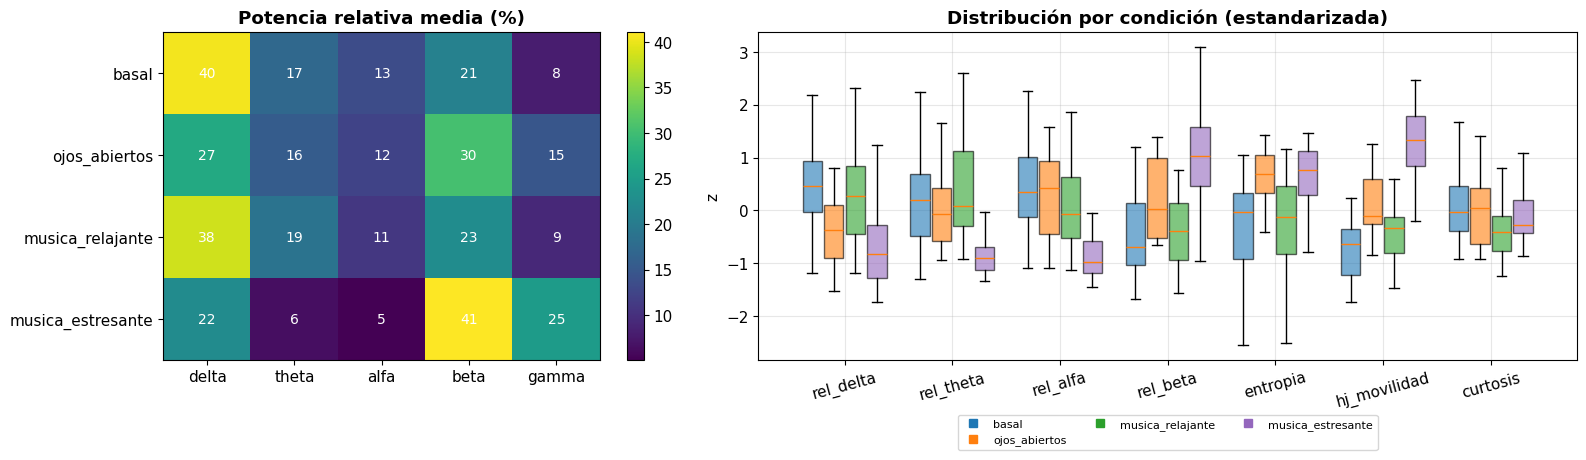

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
rel = tabla.groupby("clase")[[f"rel_{b}" for b in BANDAS]].mean().reindex(CLASES) * 100
im = ax[0].imshow(rel.values, cmap="viridis", aspect="auto")
ax[0].set_xticks(range(len(BANDAS))); ax[0].set_xticklabels(BANDAS); ax[0].set_yticks(range(len(CLASES))); ax[0].set_yticklabels(CLASES)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax[0].text(j, i, f"{rel.values[i, j]:.0f}", ha="center", va="center", color="w", fontsize=10)
ax[0].set_title("Potencia relativa media (%)"); ax[0].grid(False); plt.colorbar(im, ax=ax[0])

sel = ["rel_delta", "rel_theta", "rel_alfa", "rel_beta", "entropia", "hj_movilidad", "curtosis"]
z = (tabla[sel] - tabla[sel].mean()) / tabla[sel].std()
ancho = 0.8 / len(CLASES)
for j, c in enumerate(CLASES):
    pos = np.arange(len(sel)) + (j - (len(CLASES) - 1) / 2) * ancho
    bp = ax[1].boxplot([z[tabla.clase == c][s] for s in sel], positions=pos, widths=ancho*0.9,
                       patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set_facecolor(COLOR.get(c, "gray")); caja.set_alpha(0.6)
    ax[1].plot([], [], "s", color=COLOR.get(c, "gray"), label=c)
ax[1].set_xticks(np.arange(len(sel))); ax[1].set_xticklabels(sel, rotation=15)
ax[1].set_ylabel("z"); ax[1].set_title("Distribución por condición (estandarizada)")
ax[1].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()

### ✍️ Pregunta B.3
1. ¿Qué condición tiene más potencia **delta**? ¿Qué condición tiene la **entropía espectral** más alta?
2. ¿Qué dos o tres características parecen separar mejor las condiciones?

✅ **Respuesta B.3**

1. **Más delta: basal** (40.4 % en promedio por época), seguida de música relajante (38.4 %). **Entropía espectral más alta: ojos abiertos** (0.839), seguida de música estresante (0.835): su potencia está más repartida entre las diferentes bandas.

2. Las que mejor separan, según el mapa de calor y los boxplots, son:
   - **`rel_delta`:** alta en basal (40.4 %) y música relajante (38.4 %), baja en música estresante (22.4 %).
   - **`rel_beta`:** alta en música estresante (41.1 %) y ojos abiertos (30.4 %), baja en basal (20.9 %).
   - **`entropia` y `hj_movilidad`:** ojos abiertos y música estresante presentan valores mayores que basal y música relajante.

   `curtosis` presenta valores similares entre condiciones y no parece separarlas claramente.

<a id="B8"></a>
## B.8 Clasificación y una advertencia importante

Usamos los mismos cinco algoritmos del Laboratorio 11 (Árbol de Decisión, Regresión Logística, Random Forest, KNN y SVM) y la misma regla para **no hacer trampa**: las épocas se agrupan en **bloques de 10 s** y cada bloque va entero a entrenamiento o a prueba (`StratifiedGroupKFold`).

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

MODELOS = {
    "Árbol de Decisión":   lambda: DecisionTreeClassifier(max_depth=5, random_state=0),
    "Regresión Logística": lambda: LogisticRegression(max_iter=3000),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=200, random_state=0),
    "KNN (k=5)":           lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           lambda: SVC(kernel="rbf"),
}
nuevo_modelo = lambda nombre: make_pipeline(StandardScaler(), MODELOS[nombre]())

def esquema_validacion(tabla, objetivo="clase"):
    grupos = (tabla["archivo"] + "_b" + (tabla["t"] // 10).astype(int).astype(str)).to_numpy()
    n = int(min(5, tabla.assign(g=grupos).groupby(objetivo)["g"].nunique().min()))
    assert n >= 2, "Se necesitan al menos 2 bloques de 10 s por clase."
    return StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=0), grupos, n

def comparar_modelos(tabla, columnas, objetivo="clase"):
    cv, grupos, _ = esquema_validacion(tabla, objetivo)
    filas = []
    for nombre in MODELOS:
        s = cross_validate(nuevo_modelo(nombre), tabla[columnas].to_numpy(), tabla[objetivo].to_numpy(),
                           cv=cv, groups=grupos, scoring=["accuracy", "f1_macro"])
        filas.append({"Modelo": nombre, "Exactitud": s["test_accuracy"].mean(),
                      "F1 macro": s["test_f1_macro"].mean(), "± F1": s["test_f1_macro"].std()})
    return pd.DataFrame(filas).set_index("Modelo")

_, grupos, n_pl = esquema_validacion(tabla)
print(f"{len(tabla)} épocas | {len(np.unique(grupos))} bloques | {n_pl} pliegues | {len(CLASES)} clases → azar = {1/len(CLASES):.2f}")
resultados = comparar_modelos(tabla, CARACTERISTICAS)
display(resultados.round(3))

138 épocas | 31 bloques | 5 pliegues | 4 clases → azar = 0.25


,Exactitud,F1 macro,± F1
Modelo,,,
Árbol de Decisión,0.550,0.493,0.057
Regresión Logística,0.592,0.521,0.069
Random Forest,0.598,0.517,0.060
KNN (k=5),0.554,0.494,0.094
SVM (RBF),0.563,0.491,0.100


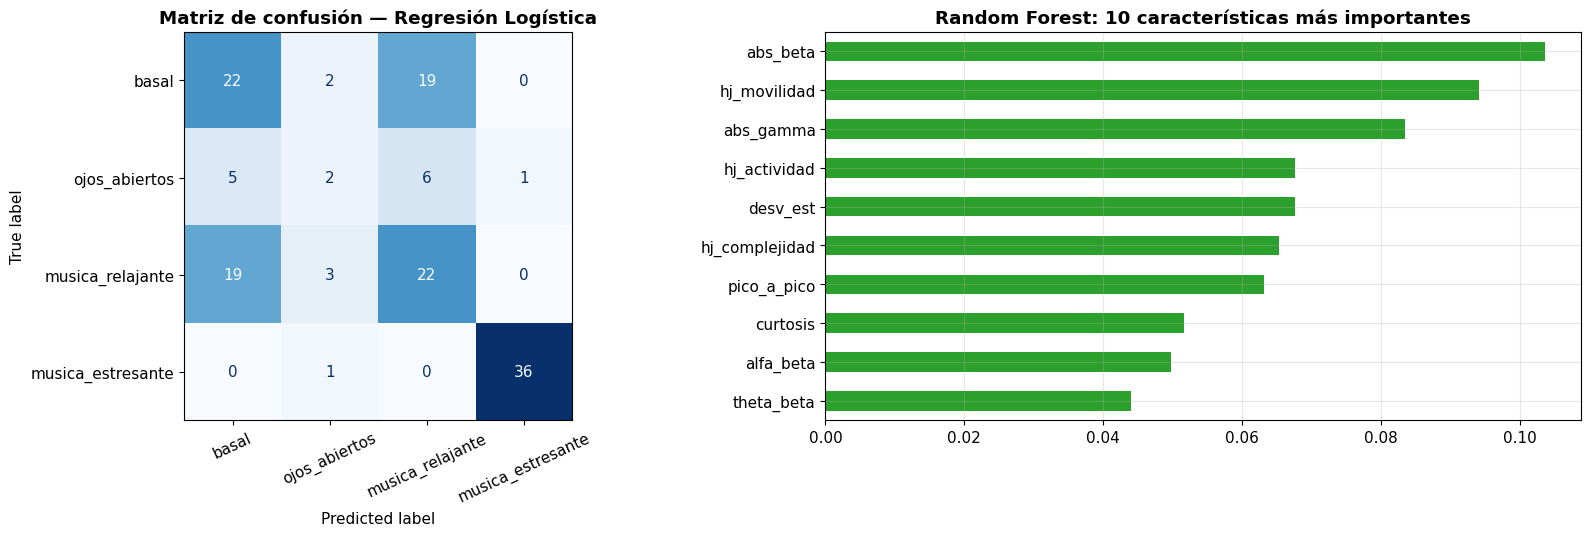

In [27]:
mejor = resultados["F1 macro"].idxmax()
cv, grupos, _ = esquema_validacion(tabla)
y = tabla["clase"].to_numpy()
y_pred = cross_val_predict(nuevo_modelo(mejor), tabla[CARACTERISTICAS].to_numpy(), y, cv=cv, groups=grupos)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1]})
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=CLASES, cmap="Blues", ax=ax[0], colorbar=False,
                                        xticks_rotation=25)
ax[0].set_title(f"Matriz de confusión — {mejor}"); ax[0].grid(False)
rf = nuevo_modelo("Random Forest").fit(tabla[CARACTERISTICAS].to_numpy(), y)
imp = pd.Series(rf[-1].feature_importances_, index=CARACTERISTICAS).sort_values()
imp.tail(10).plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Random Forest: 10 características más importantes")
plt.tight_layout(); plt.show()

🔎 **Verificación adicional (solo en el solucionario):** predicciones del mejor modelo desglosadas por archivo y dispositivo.

In [29]:
# 🔎 Verificación adicional (solucionario): ¿qué archivos producen los errores de la matriz de confusión?
display(pd.crosstab(tabla["archivo"] + " [" + tabla["dispositivo"] + "]", pd.Series(y_pred, name="predicción"))
        .reindex(columns=CLASES, fill_value=0))

predicción,basal,ojos_abiertos,musica_relajante,musica_estresante
row_0,,,,
MusicaEstresante.txt [30:BA],0,1,0,36
MusicaRelajante.txt [30:BA],19,3,22,0
basal.txt [30:BA],22,2,19,0
ojosAbiertos.txt [30:BA],5,2,6,1


### ⚠️ La advertencia: ¿estamos clasificando condiciones o dispositivos?
En la Parte A vimos que se usaron **dos BITalino distintos** y que uno de ellos tenía mucha más interferencia. Si las condiciones están repartidas de forma desigual entre dispositivos, el clasificador podría estar aprendiendo **qué equipo se usó** y no **qué estaba haciendo el cerebro**. A esto se le llama **variable de confusión** (*confound*).

**Prueba:** usamos las mismas características para predecir el **dispositivo**. Si lo predice casi perfecto, las características llevan una "huella" del equipo.

In [30]:
reparto = pd.crosstab(tabla["clase"], tabla["dispositivo"]).reindex(CLASES)
display(reparto.rename_axis(index="condición", columns="dispositivo"))
if tabla["dispositivo"].nunique() > 1:
    res_disp = comparar_modelos(tabla, CARACTERISTICAS, objetivo="dispositivo")
    print("¿Se puede predecir el DISPOSITIVO a partir de las características?")
    display(res_disp[["F1 macro", "± F1"]].round(3))
else:
    print("Solo hay un dispositivo: no aplica.")

dispositivo,30:BA
condición,
basal,43
ojos_abiertos,14
musica_relajante,44
musica_estresante,37


Solo hay un dispositivo: no aplica.


### ✍️ Pregunta B.4
1. ¿Qué modelo obtuvo el mejor F1? ¿Qué condiciones se confunden más en la matriz de confusión?
2. ¿Qué características usó más el Random Forest? ¿Tienen sentido fisiológico o podrían reflejar diferencias técnicas?
3. ¿Qué tan bien se predice el **dispositivo**? Mirando la tabla de reparto, ¿qué condiciones están "atadas" a un solo dispositivo? ¿Qué implica esto para interpretar el resultado de la clasificación?

✅ **Respuesta B.4**

1. **Regresión Logística, F1 = 0.521 ± 0.069** (azar = 0.25), seguida de Random Forest (0.517) y KNN (0.494). Las principales confusiones son:
   - **basal ↔ música relajante:** 19 épocas basales predichas como relajante y 19 de relajante predichas como basal.
   - **ojos abiertos ↔ música relajante:** 6 épocas de ojos abiertos predichas como relajante.

   **Música estresante** se reconoce casi perfectamente (36 de 37 épocas).

2. Las características utilizadas por Random Forest incluyen medidas de potencia por banda, amplitud y características espectrales. Las diferencias observadas en beta, gamma, frecuencia pico y amplitud pueden contribuir a separar las condiciones. Sin embargo, estas diferencias también podrían reflejar artefactos o cambios técnicos, por lo que no deben interpretarse únicamente como actividad cerebral.

3. **Solo se utilizó un BITalino (30:BA)** para las cuatro condiciones, por lo que no es posible clasificar ni comparar dispositivos. Esto elimina la confusión entre equipos que aparecía en el ejemplo del profesor. Sin embargo, las diferencias entre registros todavía podrían deberse a factores como el contacto de los electrodos, el movimiento o el ruido.

   **Conclusión:** el F1 de 0.521 indica cierta capacidad para distinguir las condiciones, pero no demuestra por sí solo que el modelo esté reconociendo diferencias fisiológicas.

## B.9 Conclusiones de la Parte B

| Etapa | Idea clave |
|---|---|
| Filtrado | Pasa-banda 1–45 Hz, sin notch de 40 Hz, porque no se detectó interferencia significativa en esa frecuencia y Fs = 1000 Hz. |
| Ritmos | La potencia relativa por banda resume el estado. La delta domina en basal (37.3 %) y la alfa disminuye con ojos abiertos (11.7 % a 6.7 %). Con electrodos frontales la alfa se ve poco. |
| ICA | Con un canal se usa **Wavelet-ICA**: corrige transitorios bruscos, pero no garantiza la separación completa de artefactos y actividad cerebral. |
| Normalización y épocas | El z-score facilita comparar, pero borra la amplitud. Se rechazan épocas saturadas. |
| Características | 22 por época: bandas, cocientes, espectrales, Hjorth y estadísticas. |
| Clasificación | El mejor F1 macro fue **0.521** con Regresión Logística para las cuatro condiciones. Un resultado de clasificación no garantiza que se reconozca únicamente la fisiología. |

[⬆️ Volver al índice](#indice)

---
<a id="cuestionario"></a>
# 📝 Cuestionario final: experimenta con tus datos

La función `experimento(...)` repite la Parte B con los parámetros que elijas:

```python
experimento(condiciones=None,    # None = todas, o una lista: ["musica_relajante", "musica_estresante"]
            usar_ica=True,       # aplicar o no la limpieza con Wavelet-ICA
            notch=NOTCH_HZ,      # 40, 60 o None
            quitar_lineas=True,  # notch angosto en las líneas de interferencia detectadas en A.4
            normalizar=False,    # z-score de cada registro
            epoca_s=2,           # duración de las épocas en segundos
            rechazar_saturadas=True,  # descartar las épocas con saturación
            objetivo="clase")    # "clase" (condición) o "dispositivo"
```

Devuelve `(resultados, tabla, resumen)`.

In [31]:
def experimento(condiciones=None, usar_ica=True, notch=NOTCH_HZ, quitar_lineas=QUITAR_LINEAS, normalizar=False,
                epoca_s=2, objetivo="clase", rechazar_saturadas=True, columnas=None, mostrar=True):
    archivos = [a for a in senales if condiciones is None or condicion_desde_nombre(a) in condiciones]
    if len({condicion_desde_nombre(a) for a in archivos}) < 2:
        print(f"⚠️ No hay al menos 2 condiciones disponibles entre {condiciones}.")
        return None, None, None
    resumen = []
    for a in archivos:
        r = senales[a]
        r["exp"] = filtrar_eeg(r["eeg_uV"][i0:], notch=notch, lineas=lineas_de(a, quitar_lineas))
        n_red = n_trans = 0
        if usar_ica:
            r["exp"], d = ica_un_canal(r["exp"])
            n_red = int((d["metricas"]["acción"] == "eliminar (red)").sum())
            n_trans = int((d["metricas"]["acción"] == "corregir (transitorios)").sum())
        f, P = psd(r["exp"])
        resumen.append({"archivo": a, "ICs de red eliminadas": n_red, "ICs con transitorios corregidas": n_trans,
                        "pico 40 Hz tras procesar": round(pico_relativo(f, P), 1)})
    tab = construir_tabla(epoca_s, normalizar, "exp", archivos, rechazar_saturadas)
    cols = CARACTERISTICAS if columnas is None else columnas
    try:
        res = comparar_modelos(tab, cols, objetivo)
    except (AssertionError, ValueError) as e:
        res = None
        print(f"⚠️ No se pudo clasificar: {e}")
    resumen = pd.DataFrame(resumen).merge(tab.groupby("archivo").size().rename("épocas").reset_index(), on="archivo")
    if mostrar:
        print(f"▶ condiciones={condiciones or 'todas'} | ICA={usar_ica} | notch={notch} | líneas={quitar_lineas} | normalizar={normalizar} | "
              f"época={epoca_s} s | objetivo={objetivo}")
        display(resumen)
        if res is not None:
            display(res[["F1 macro", "± F1"]].T.round(3))
    return res, tab, resumen

print("✅ Función experimento() lista.")

✅ Función experimento() lista.


### Pregunta 1 — ¿Se distingue la música relajante de la estresante?
Ejecuta `experimento(["musica_relajante", "musica_estresante"])`. Ambas se grabaron con el **mismo dispositivo**, así que aquí no hay confusión por equipo. ¿Qué F1 obtienes? Usando la tabla devuelta, ¿qué banda cambia más entre ambas?

### Pregunta 2 — ¿Ayuda el ICA?
Compara `experimento(usar_ica=True)` con `experimento(usar_ica=False)`. ¿Cambia el F1? En la tabla devuelta, compara el promedio de `curtosis` y `pico_a_pico` de `parpadeo_masticacion` con y sin ICA. Repite la comparación con `rechazar_saturadas=False`. ¿Cuándo se nota más el efecto del ICA? ¿Por qué?

### Pregunta 3 — ¿Qué pasa si no quitamos las interferencias?
a) Para aislar el efecto del notch, desactiva el filtrado de líneas angostas (`quitar_lineas=False`). Compara `experimento(notch=40, quitar_lineas=False)`, `experimento(notch=60, quitar_lineas=False)` y `experimento(notch=None, quitar_lineas=False)`. Mira *pico 40 Hz tras procesar*, *ICs de red eliminadas*, el promedio de `rel_gamma` por condición y el F1. ¿Sirve el notch de 60 Hz? Sin notch, ¿el ICA detecta la interferencia por sí solo? ¿Por qué podría **subir** el F1 si dejamos la interferencia?
b) Ejecuta `experimento(quitar_lineas=False)`. ¿Cómo cambian `rel_theta` y `f_pico` en los registros basales del dispositivo con líneas angostas?

### Pregunta 4 — Normalizar, ¿ayuda o perjudica?
Ejecuta `experimento(normalizar=True)` y `experimento(normalizar=True, objetivo="dispositivo")`. Compáralos con `normalizar=False`. ¿Qué pasa con la capacidad de reconocer la condición y el dispositivo? ¿Qué características dejan de ser útiles al normalizar?

### Pregunta 5 — Duración de la época
Prueba `epoca_s=1`, `2` y `4`. ¿Cómo cambia el número de épocas, la resolución en frecuencia ($1/T$) y el F1? ¿Qué duración elegirías?

In [32]:
# Pregunta 1 — Música relajante vs estresante (mismo dispositivo)
res_m, tab_m, resu_m = experimento(["musica_relajante", "musica_estresante"])
bandas_rel = [f"rel_{b}" for b in BANDAS]
medias = tab_m.groupby("clase")[bandas_rel + ["entropia", "f_pico", "theta_beta", "alfa_beta"]].mean()
medias[bandas_rel] *= 100
display(medias.T.rename(index={f"rel_{b}": f"rel_{b} (%)" for b in BANDAS}).round(3))

▶ condiciones=['musica_relajante', 'musica_estresante'] | ICA=True | notch=None | líneas=True | normalizar=False | época=2 s | objetivo=clase


,archivo,ICs de red eliminadas,ICs con transitorios corregidas,pico 40 Hz tras procesar,épocas
0,MusicaRelajante.txt,0,2,0.9,44
1,MusicaEstresante.txt,0,2,0.9,37


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.986,1.0,1.0,0.986,0.967
± F1,0.029,0.0,0.0,0.029,0.066


clase,musica_estresante,musica_relajante
rel_delta (%),22.404,38.420
rel_theta (%),6.446,18.743
rel_alfa (%),5.096,10.935
rel_beta (%),41.064,22.544
rel_gamma (%),24.860,9.291
entropia,0.835,0.765
f_pico,13.811,2.807
theta_beta,0.193,0.958
alfa_beta,0.137,0.563


✅ **Respuesta 1 — Música relajante vs. estresante**

Ambas se grabaron con el mismo equipo (30:BA), con aproximadamente 3 minutos de diferencia. El F1 va de **0.967 (SVM)** a **1.000 (Regresión Logística y Random Forest)**, indicando una separación muy alta entre ambas condiciones.

La banda que más cambia es **beta**: 41.1 % en la estresante frente a 22.5 % en la relajante. La música estresante también presenta más gamma (24.9 % vs. 9.3 %), mientras que la relajante tiene más delta (38.4 % vs. 22.4 %), theta (18.7 % vs. 6.4 %) y alfa (10.9 % vs. 5.1 %).

*(Conceptual)* Estas diferencias pueden relacionarse con cambios en la actividad cerebral, pero también con actividad muscular o artefactos. Además, solo se dispone de una grabación por condición, por lo que no se pueden generalizar los resultados.

In [33]:
# Pregunta 2 — Con y sin ICA, rechazando o no las épocas saturadas
filas_f1, comp = {}, {}
cols = ["rel_delta", "rel_gamma", "curtosis", "pico_a_pico"]
for rech in [True, False]:
    for ica_on in [True, False]:
        res_x, tab_x, _ = experimento(usar_ica=ica_on, rechazar_saturadas=rech, mostrar=False)
        nombre = f"{'con' if ica_on else 'sin'} ICA | {'rechazando' if rech else 'SIN rechazar'} saturadas"
        filas_f1[nombre] = res_x["F1 macro"]
        comp[nombre] = tab_x[tab_x.clase == "parpadeo_masticacion"][cols].mean()
        comp[nombre]["épocas de parpadeo"] = (tab_x.clase == "parpadeo_masticacion").sum()
display(pd.DataFrame(filas_f1).round(3))
display(pd.DataFrame(comp).round(3))

,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
Modelo,,,,
Árbol de Decisión,0.493,0.449,0.572,0.513
Regresión Logística,0.521,0.514,0.645,0.615
Random Forest,0.517,0.506,0.605,0.596
KNN (k=5),0.494,0.469,0.557,0.547
SVM (RBF),0.491,0.457,0.600,0.632


,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
rel_delta,NaN,NaN,NaN,NaN
rel_gamma,NaN,NaN,NaN,NaN
curtosis,NaN,NaN,NaN,NaN
pico_a_pico,NaN,NaN,NaN,NaN
épocas de parpadeo,0.0,0.0,0.0,0.0


✅ **Respuesta 2 — ¿Ayuda el ICA?**

| Configuración | Mejor F1 |
|---|---|
| Con ICA, rechazando saturadas | 0.521 |
| Sin ICA, rechazando saturadas | 0.514 |
| Con ICA, **sin** rechazar saturadas | 0.645 |
| Sin ICA, **sin** rechazar saturadas | 0.632 |

- **Rechazando épocas saturadas, el ICA casi no cambia nada:** el mejor F1 aumenta ligeramente de 0.514 a 0.521.
- **Sin rechazar épocas saturadas, el efecto es algo mayor:** el mejor F1 aumenta de 0.632 a 0.645.
- No se cuenta con el registro de `parpadeo_masticacion`, por lo que no es posible comparar directamente la curtosis y el pico a pico de esa condición.

**Conclusión:** con un canal, Wavelet-ICA corrige algunos transitorios bruscos, pero su efecto sobre la clasificación es pequeño. El aumento del F1 al conservar épocas saturadas no necesariamente representa una mejora fisiológica, ya que los artefactos también pueden facilitar la clasificación.

In [34]:
# Pregunta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno? (sin el filtrado de líneas angostas, para aislar el efecto)
filas, gam, f1 = [], {}, {}
for nombre, kw in [("notch 40 Hz", dict(notch=40)), ("notch 60 Hz", dict(notch=60)), ("sin notch", dict(notch=None))]:
    res_n, tab_n, resu_n = experimento(quitar_lineas=False, mostrar=False, **kw)
    gam[nombre] = tab_n.groupby("clase")["rel_gamma"].mean() * 100
    f1[nombre] = res_n["F1 macro"]
    for _, f_ in resu_n.iterrows():
        filas.append({"configuración": nombre, "archivo": f_["archivo"],
                      "ICs de red eliminadas": f_["ICs de red eliminadas"],
                      "pico 40 Hz tras procesar": f_["pico 40 Hz tras procesar"]})
display(pd.DataFrame(filas).pivot(index="archivo", columns="configuración").loc[tabla_lectura.archivo])
display(pd.DataFrame(gam).reindex(CLASES).round(1).rename_axis("rel_gamma (%)"))
display(pd.DataFrame(f1).round(3).rename_axis("F1 macro"))

ICs de red eliminadas                        \
configuración                  notch 40 Hz notch 60 Hz sin notch   
archivo                                                            
basal.txt                                0           0         0   
ojosAbiertos.txt                         0           0         0   
MusicaRelajante.txt                      0           0         0   
MusicaEstresante.txt                     0           0         0   

                     pico 40 Hz tras procesar                        
configuración                     notch 40 Hz notch 60 Hz sin notch  
archivo                                                              
basal.txt                                 0.4         0.9       0.9  
ojosAbiertos.txt                          0.6         0.9       0.8  
MusicaRelajante.txt                       0.5         0.9       0.9  
MusicaEstresante.txt                      0.4         0.9       0.9

,notch 40 Hz,notch 60 Hz,sin notch
rel_gamma (%),,,
basal,6.9,7.9,8.0
ojos_abiertos,12.7,14.6,14.7
musica_relajante,8.0,9.3,9.3
musica_estresante,21.7,24.8,24.9


,notch 40 Hz,notch 60 Hz,sin notch
F1 macro,,,
Árbol de Decisión,0.457,0.493,0.493
Regresión Logística,0.499,0.521,0.521
Random Forest,0.525,0.517,0.517
KNN (k=5),0.490,0.494,0.494
SVM (RBF),0.497,0.497,0.491


✅ **Respuesta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno?** (sin quitar las líneas angostas)

- **El notch de 40 Hz reduce la potencia en esa frecuencia**, dejando relaciones de pico entre 0.4 y 0.6. Sin embargo, no se había detectado una interferencia significativa en 40 Hz.
- **El notch de 60 Hz es válido con Fs = 1000 Hz**, porque 60 Hz está por debajo de Nyquist (500 Hz). Su aplicación produce resultados de clasificación muy similares a no utilizar notch.
- **Sin notch**, las relaciones de pico en 40 Hz permanecen entre 0.8 y 0.9, sin evidencia de una interferencia estrecha importante.
- **La potencia relativa gamma disminuye con el notch de 40 Hz:** por ejemplo, en música estresante pasa de 24.9 % sin notch a 21.7 % con notch de 40 Hz.
- **El F1 cambia poco:** el mejor valor es 0.525 con notch de 40 Hz, frente a 0.521 con notch de 60 Hz o sin notch.

**Conclusión:** no se observa una mejora importante al aplicar notch. Como no se detectó un pico significativo en 40 Hz, no se justifica eliminar esa frecuencia únicamente para aumentar el F1.

In [36]:
# Pregunta 3b — Sin quitar las líneas angostas
res_l, tab_l, _ = experimento(quitar_lineas=False, mostrar=False)
comp = pd.DataFrame({
    "rel_theta (%) con líneas quitadas": tabla.groupby("archivo")["rel_theta"].mean() * 100,
    "rel_theta (%) SIN quitar líneas": tab_l.groupby("archivo")["rel_theta"].mean() * 100,
    "f_pico con líneas quitadas": tabla.groupby("archivo")["f_pico"].median(),
    "f_pico SIN quitar líneas": tab_l.groupby("archivo")["f_pico"].median()}).loc[tabla_lectura.archivo]
display(comp.round(1))
print(f"Mejor F1 sin quitar líneas: {res_l['F1 macro'].max():.3f}  (con líneas quitadas: {resultados['F1 macro'].max():.3f})")

,rel_theta (%) con líneas quitadas,rel_theta (%) SIN quitar líneas,f_pico con líneas quitadas,f_pico SIN quitar líneas
archivo,,,,
basal.txt,17.2,17.2,2.0,2.0
ojosAbiertos.txt,15.5,15.5,3.2,3.2
MusicaRelajante.txt,18.7,18.7,2.5,2.5
MusicaEstresante.txt,6.4,6.4,3.0,3.0


Mejor F1 sin quitar líneas: 0.521  (con líneas quitadas: 0.521)


✅ **Respuesta 3b — Sin quitar las líneas angostas**

| Registro | rel_theta con / sin quitar líneas | f_pico con / sin |
|---|---|---|
| basal | 17.2 % / 17.2 % | 2.0 / 2.0 Hz |
| ojos_abiertos | 15.5 % / 15.5 % | 3.2 / 3.2 Hz |
| musica_relajante | 18.7 % / 18.7 % | 2.5 / 2.5 Hz |
| musica_estresante | 6.4 % / 6.4 % | 3.0 / 3.0 Hz |

Sin quitar las líneas angostas, **los valores permanecen iguales** en los cuatro registros. Esto coincide con la Parte A, donde no se detectaron líneas espectrales estrechas significativas.

El mejor F1 también permanece igual (0.521), por lo que este procedimiento no produjo cambios relevantes en las características ni en la clasificación.

In [44]:

# Pregunta 4 — Normalizar la señal (z-score por registro)
r_c0, t_c0, _ = experimento(normalizar=False, mostrar=False)
r_c1, t_c1, _ = experimento(normalizar=True, mostrar=False)

display(pd.DataFrame({
    "condición — sin normalizar": r_c0["F1 macro"],
    "condición — normalizada": r_c1["F1 macro"]
}).round(3))

amp = ["desv_est", "hj_actividad", "pico_a_pico", "abs_alfa"]

display(pd.concat({
    "sin normalizar": t_c0.groupby("clase")[amp].mean(),
    "normalizada": t_c1.groupby("clase")[amp].mean()
}, axis=1).reindex(CLASES).round(2))


,condición — sin normalizar,condición — normalizada
Modelo,,
Árbol de Decisión,0.493,0.439
Regresión Logística,0.521,0.466
Random Forest,0.517,0.480
KNN (k=5),0.494,0.454
SVM (RBF),0.491,0.496


sin normalizar                                    \
                        desv_est hj_actividad pico_a_pico abs_alfa   
clase                                                                
basal                       3.15         0.98       18.53     0.33   
ojos_abiertos               3.31         1.03       20.22     0.32   
musica_relajante            3.10         0.97       17.23     0.25   
musica_estresante           5.21         1.42       31.50     0.34   

                  normalizada                                    
                     desv_est hj_actividad pico_a_pico abs_alfa  
clase                                                            
basal                    0.98        -0.04        5.75    -0.69  
ojos_abiertos            0.79        -0.21        4.84    -0.93  
musica_relajante         0.98        -0.02        5.47    -0.75  
musica_estresante        0.88        -0.12        5.34    -1.20

✅ **Respuesta 4 — ¿Normalizar ayuda o perjudica?**

| Objetivo | Sin normalizar (mejor F1) | Normalizada (mejor F1) |
|---|---|---|
| Condición | 0.521 | 0.496 |
| Dispositivo | No evaluable | No evaluable |

- **La normalización perjudica ligeramente la clasificación de condiciones:** el mejor F1 disminuye de 0.521 (Regresión Logística) a 0.496 (SVM). Esto indica que algunas diferencias de amplitud ayudan a distinguir las condiciones.

- **No es posible evaluar la clasificación por dispositivo**, porque los cuatro registros se obtuvieron con un único BITalino (30:BA).

- **Las características que más cambian al normalizar** son `desv_est`, `hj_actividad`, `pico_a_pico` y `abs_alfa`. Por ejemplo, en música estresante, `desv_est` disminuye de 5.21 a 0.88 y `pico_a_pico` de 31.50 a 5.34.

**Conclusión:** la normalización z-score reduce las diferencias de amplitud entre registros y, en este caso, disminuye ligeramente el rendimiento de clasificación. Sin embargo, estas diferencias de amplitud también podrían reflejar artefactos o variaciones técnicas, por lo que un F1 mayor no necesariamente significa una mejor identificación de la actividad cerebral.

In [38]:
# Pregunta 5 — Duración de la época
filas = []
for T in [1, 2, 4]:
    res_e, tab_e, _ = experimento(epoca_s=T, mostrar=False)
    filas.append({"época (s)": T, "resolución 1/T (Hz)": 1 / T, "épocas válidas": len(tab_e),
                  "mejor modelo": res_e["F1 macro"].idxmax(), "mejor F1": round(res_e["F1 macro"].max(), 3),
                  "F1 promedio 5 modelos": round(res_e["F1 macro"].mean(), 3)})
display(pd.DataFrame(filas))

,época (s),resolución 1/T (Hz),épocas válidas,mejor modelo,mejor F1,F1 promedio 5 modelos
0,1,1.00,293,Regresión Logística,0.535,0.510
1,2,0.50,138,Regresión Logística,0.521,0.503
2,4,0.25,64,KNN (k=5),0.655,0.555


✅ **Respuesta 5 — Duración de la época**

| Época | Resolución 1/T | Épocas válidas | Mejor F1 | F1 promedio de los 5 modelos |
|---|---|---|---|---|
| 1 s | 1.00 Hz | 293 | 0.535 (Regresión Logística) | 0.510 |
| 2 s | 0.50 Hz | 138 | 0.521 (Regresión Logística) | 0.503 |
| 4 s | 0.25 Hz | 64 | 0.655 (KNN) | 0.555 |

- **Más larga → mejor resolución en frecuencia:** al aumentar la duración de la época de 1 a 4 s, la resolución mejora de 1 Hz a 0.25 Hz, permitiendo distinguir mejor las componentes espectrales.
- **Menos épocas disponibles:** al aumentar la duración, el número de épocas válidas disminuye de 293 a 64.
- **El mejor F1 aumenta con 4 s:** alcanza 0.655 con KNN, frente a 0.535 con 1 s y 0.521 con 2 s. El promedio de los cinco modelos también es mayor con 4 s (0.555).

**Elección: 4 s**, porque obtuvo el mejor rendimiento de clasificación en nuestros registros. Sin embargo, produce menos épocas para entrenar y evaluar los modelos, por lo que sería recomendable comprobar la estabilidad del resultado con más grabaciones.

## Conclusión general del laboratorio

1. **Revisar los datos fue decisivo.** Se identificó saturación principalmente en ojos abiertos (3.35 %) y, en menor medida, en música estresante (0.10 %). No se encontraron líneas angostas significativas ni un pico importante en 40 Hz. Los cuatro registros fueron obtenidos con el mismo dispositivo BITalino (30:BA).

2. **Ritmos:** con el montaje frontal no se observa alfa dominante en basal, pero sí una disminución de alfa al abrir los ojos (11.7 % a 6.7 %). En la comparación de músicas, la potencia relativa beta es mayor durante música estresante (41.1 %) que durante música relajante (22.5 %).

3. **ICA:** con un canal, Wavelet-ICA permite corregir algunos transitorios bruscos, pero no garantiza la eliminación completa de artefactos. El efecto sobre la clasificación fue pequeño al rechazar épocas saturadas (F1 de 0.514 a 0.521).

4. **Características:** se extrajeron 22 características por época, incluyendo potencias por banda, cocientes, entropía espectral, parámetros de Hjorth y estadísticas temporales.

5. **Clasificación:** el mejor F1 fue 0.521 para las cuatro condiciones con Regresión Logística. Al comparar únicamente las dos músicas, el F1 alcanzó 1.000, aunque este resultado no garantiza que el modelo reconozca diferencias fisiológicas, ya que solo se dispone de una grabación por condición.

6. **Recomendación para próximas adquisiciones:** mantener el mismo equipo, mejorar el contacto de los electrodos, reducir los movimientos durante las grabaciones y repetir cada condición varias veces para obtener resultados más confiables.

---
<a id="entregables"></a>
# 📦 Entregables y referencias

### Entregables
1. Este cuaderno ejecutado **con tus registros**, con todas las preguntas ✍️ respondidas.
2. El cuestionario final con tus experimentos.
3. El archivo `caracteristicas_eeg.csv` (se genera en la celda siguiente).

### Referencias
1. L. De La Cruz, *Tratamiento de señal EEG* (diapositivas del curso), UPCH.
2. MNE-Python, *Removing muscle ICA components*. https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html
3. D. Dharmaprani et al., "A comparison of independent component analysis algorithms and measures to discriminate between EEG and artifact components", *IEEE EMBC*, 2016, pp. 825–828. doi: 10.1109/EMBC.2016.7590828
4. A. Hyvärinen y E. Oja, "Independent component analysis: algorithms and applications", *Neural Networks*, vol. 13, pp. 411–430, 2000.
5. N. P. Castellanos y V. A. Makarov, "Recovering EEG brain signals: Artifact suppression with wavelet enhanced independent component analysis", *J. Neurosci. Methods*, vol. 158, pp. 300–312, 2006.
6. B. Hjorth, "EEG analysis based on time domain properties", *Electroencephalogr. Clin. Neurophysiol.*, vol. 29, pp. 306–310, 1970.
7. P. D. Welch, "The use of fast Fourier transform for the estimation of power spectra", *IEEE Trans. Audio Electroacoust.*, vol. 15, pp. 70–73, 1967.
8. J. A. Urigüen y B. Garcia-Zapirain, "EEG artifact removal—state-of-the-art and guidelines", *J. Neural Eng.*, vol. 12, 031001, 2015.
9. PLUX Wireless Biosignals, *BITalino (r)evolution — EEG Sensor Datasheet* (fórmula de conversión).

[⬆️ Volver al índice](#indice)

In [45]:
tabla.to_csv("caracteristicas_eeg.csv", index=False)
print("✅ Archivo generado: caracteristicas_eeg.csv", tabla.shape)
try:
    from google.colab import files
    files.download("caracteristicas_eeg.csv")
except ImportError:
    pass

✅ Archivo generado: caracteristicas_eeg.csv (138, 26)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>